In [ ]:
!pip install lime shap

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 3.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=9604fe1fff8da0462f8215cd1c70418b9a885606dac47ccec1984e048f2806e2
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime


In [ ]:
import pandas as pd
import numpy as np
import shap
import lime
import lime.lime_tabular
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.inspection import PartialDependenceDisplay
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.tree import plot_tree
from sklearn.metrics import mean_absolute_error
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import AdaBoostRegressor
import warnings
warnings.filterwarnings('ignore')

In [ ]:
file_link = 'https://drive.google.com/file/d/1DGVvAxk6dYEkviu5lvhGEqrRHaxrpFI7/view?usp=sharing'

# get the id part of the file
id = file_link.split("/")[-2]

# creating a new link using the id for better readability of csv file in pandas
new_link = f'https://drive.google.com/uc?id={id}'
df = pd.read_csv(new_link)

# **EDA**

In [ ]:
df.shape

(3500, 24)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        3500 non-null   int64  
 1   age                       3500 non-null   int64  
 2   gender                    3500 non-null   object 
 3   region                    3500 non-null   object 
 4   income_level              3500 non-null   object 
 5   education_level           3500 non-null   object 
 6   daily_role                3500 non-null   object 
 7   device_hours_per_day      3500 non-null   float64
 8   phone_unlocks             3500 non-null   int64  
 9   notifications_per_day     3500 non-null   int64  
 10  social_media_mins         3500 non-null   int64  
 11  study_mins                3500 non-null   int64  
 12  physical_activity_days    3500 non-null   float64
 13  sleep_hours               3500 non-null   float64
 14  sleep_qu

In [ ]:
df.describe()

,id,age,device_hours_per_day,phone_unlocks,notifications_per_day,social_media_mins,study_mins,physical_activity_days,sleep_hours,sleep_quality,anxiety_score,depression_score,stress_level,happiness_score,focus_score,high_risk_flag,productivity_score,digital_dependence_score
count,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000
mean,1750.500000,28.078571,7.317677,147.107429,335.117143,159.362857,108.116571,3.350000,7.254481,2.708848,7.183858,8.830000,5.076560,6.418568,41.598600,0.201429,65.299301,36.684152
std,1010.507298,9.352385,3.239838,67.770656,239.678612,132.748048,79.796273,1.877976,1.291879,1.101105,5.043220,5.738959,3.403503,3.019828,23.764574,0.401125,9.664716,14.115504
min,1.000000,13.000000,0.280000,9.000000,22.000000,0.000000,0.000000,0.000000,3.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,33.000000,5.600000
25%,875.750000,21.000000,4.867500,96.000000,170.000000,68.000000,42.000000,2.000000,6.410545,1.919438,4.000000,4.000000,1.341488,4.000000,24.750000,0.000000,59.000000,26.200000
50%,1750.500000,27.000000,6.760000,136.000000,268.000000,119.000000,102.000000,3.000000,7.291580,2.907819,6.000000,8.000000,4.809726,7.500000,44.000000,0.000000,65.299301,35.300000
75%,2625.250000,34.000000,9.152500,187.000000,434.000000,204.000000,163.000000,5.000000,8.162298,3.276968,8.845008,13.000000,8.794302,8.900000,59.000000,0.000000,71.000000,45.100000
max,3500.000000,50.000000,17.160000,374.000000,1211.000000,631.000000,418.000000,7.000000,11.004566,5.000000,27.154217,27.000000,10.000000,10.000000,100.000000,1.000000,95.000000,89.200000


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.keys()

Index(['id', 'age', 'gender', 'region', 'income_level', 'education_level',
       'daily_role', 'device_hours_per_day', 'phone_unlocks',
       'notifications_per_day', 'social_media_mins', 'study_mins',
       'physical_activity_days', 'sleep_hours', 'sleep_quality',
       'anxiety_score', 'depression_score', 'stress_level', 'happiness_score',
       'focus_score', 'high_risk_flag', 'device_type', 'productivity_score',
       'digital_dependence_score'],
      dtype='object')

In [ ]:
df.isnull().sum()

,0
id,0
age,0
gender,0
region,0
income_level,0
education_level,0
daily_role,0
device_hours_per_day,0
phone_unlocks,0
notifications_per_day,0


In [ ]:
df.nunique().sort_values()

,0
gender,2
high_risk_flag,2
education_level,4
income_level,4
device_type,4
daily_role,5
region,6
physical_activity_days,8
depression_score,28
age,38


In [ ]:
df.dtypes.value_counts()

,count
float64,11
int64,7
object,6


In [ ]:
#check the cat and num column name
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
num_cols = df.select_dtypes(include=np.number).columns.tolist()
print("Categorical Variables:")
print(cat_cols)
print("Numerical Variables:")
print(num_cols)

Categorical Variables:
['gender', 'region', 'income_level', 'education_level', 'daily_role', 'device_type']
Numerical Variables:
['id', 'age', 'device_hours_per_day', 'phone_unlocks', 'notifications_per_day', 'social_media_mins', 'study_mins', 'physical_activity_days', 'sleep_hours', 'sleep_quality', 'anxiety_score', 'depression_score', 'stress_level', 'happiness_score', 'focus_score', 'high_risk_flag', 'productivity_score', 'digital_dependence_score']


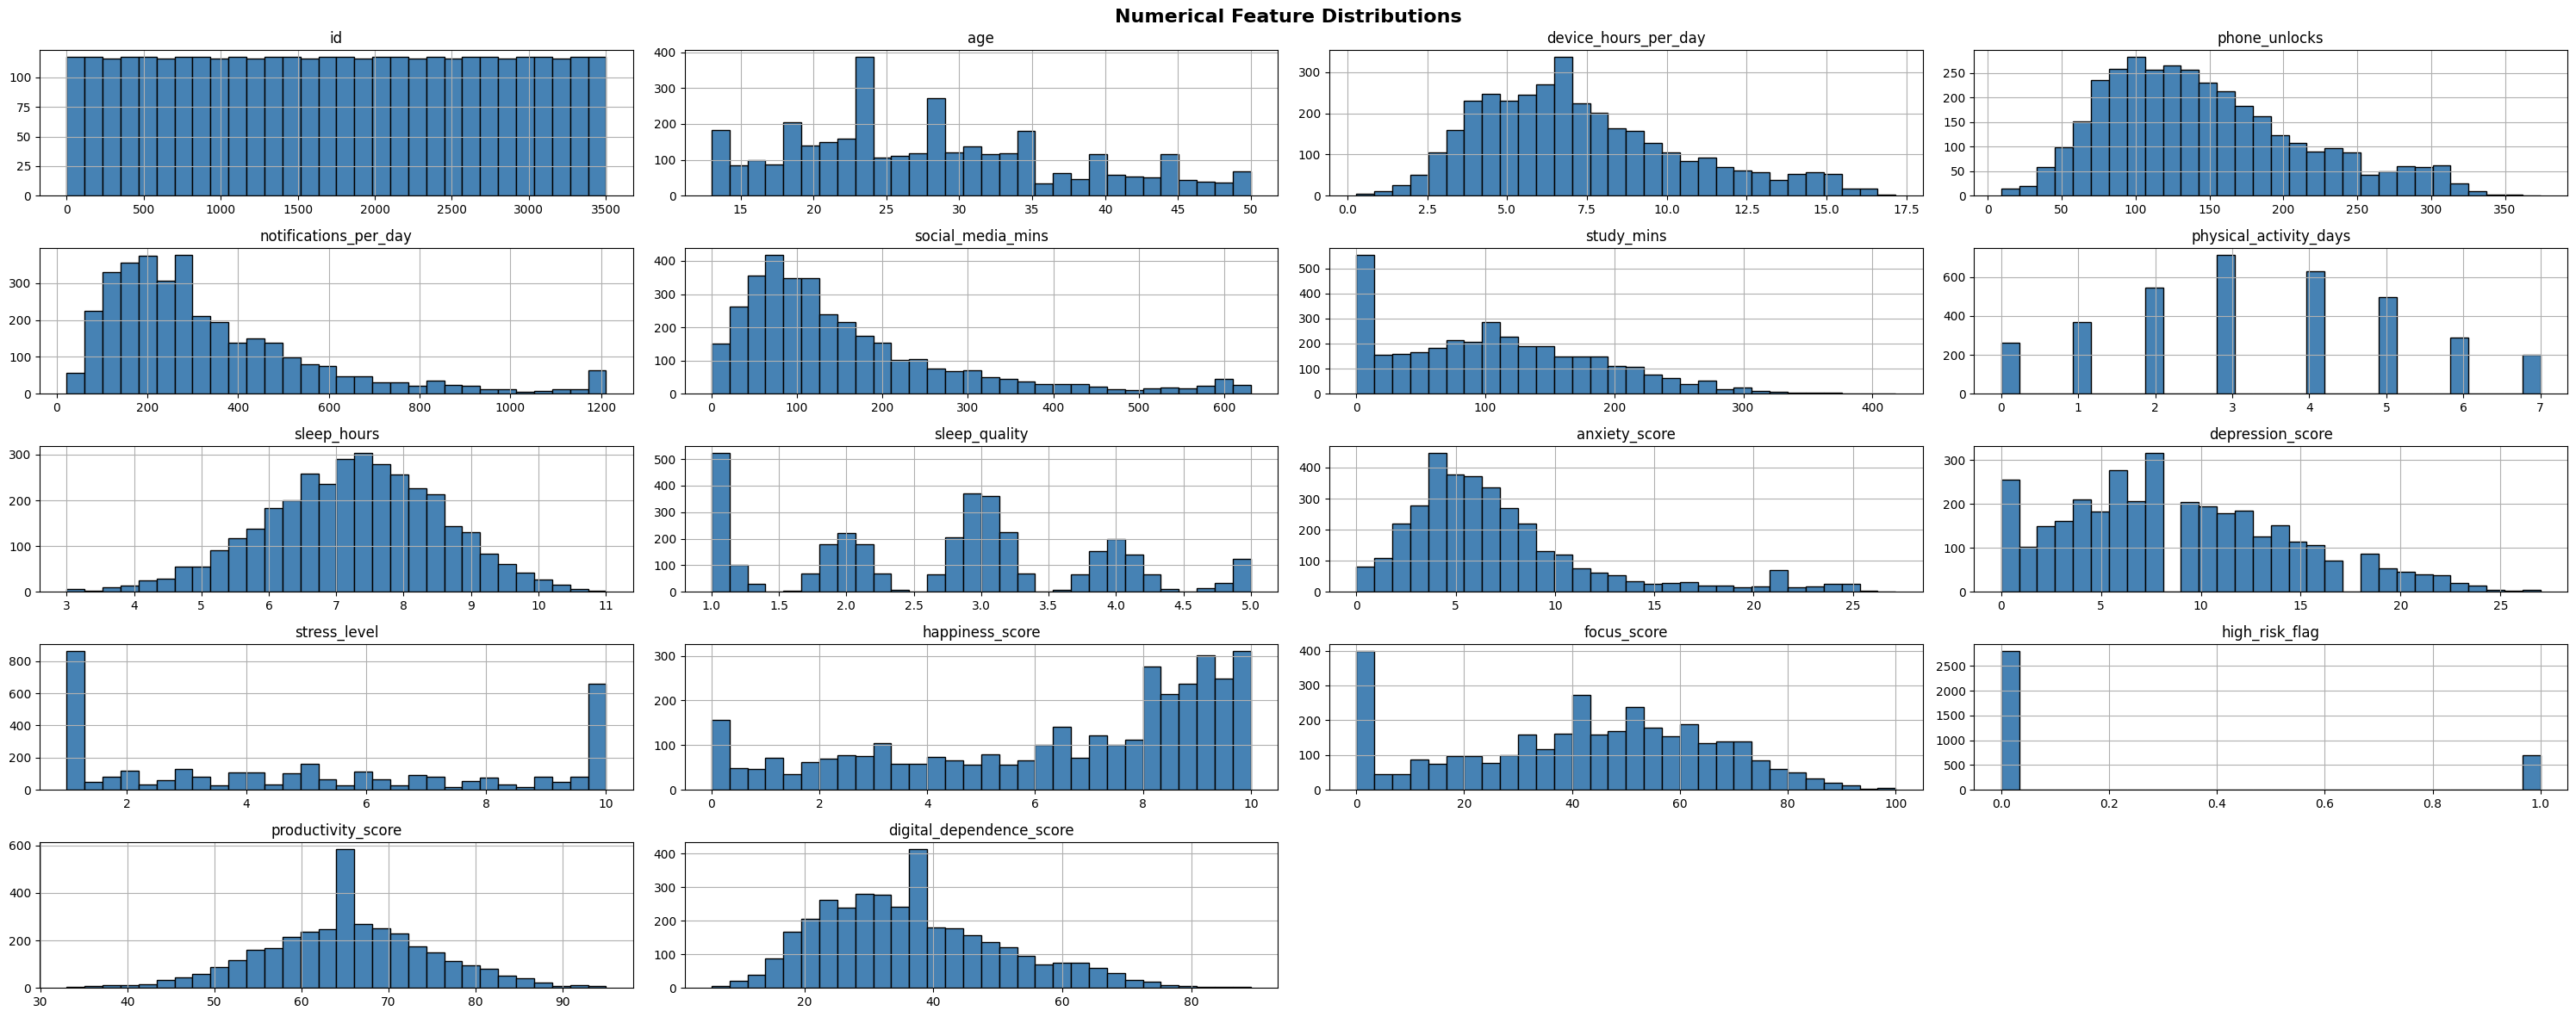

In [ ]:
# Distribution of each numerical feature
df[num_cols].hist(figsize=(30, 12), bins=30, edgecolor='black', color='steelblue')
plt.suptitle('Numerical Feature Distributions', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

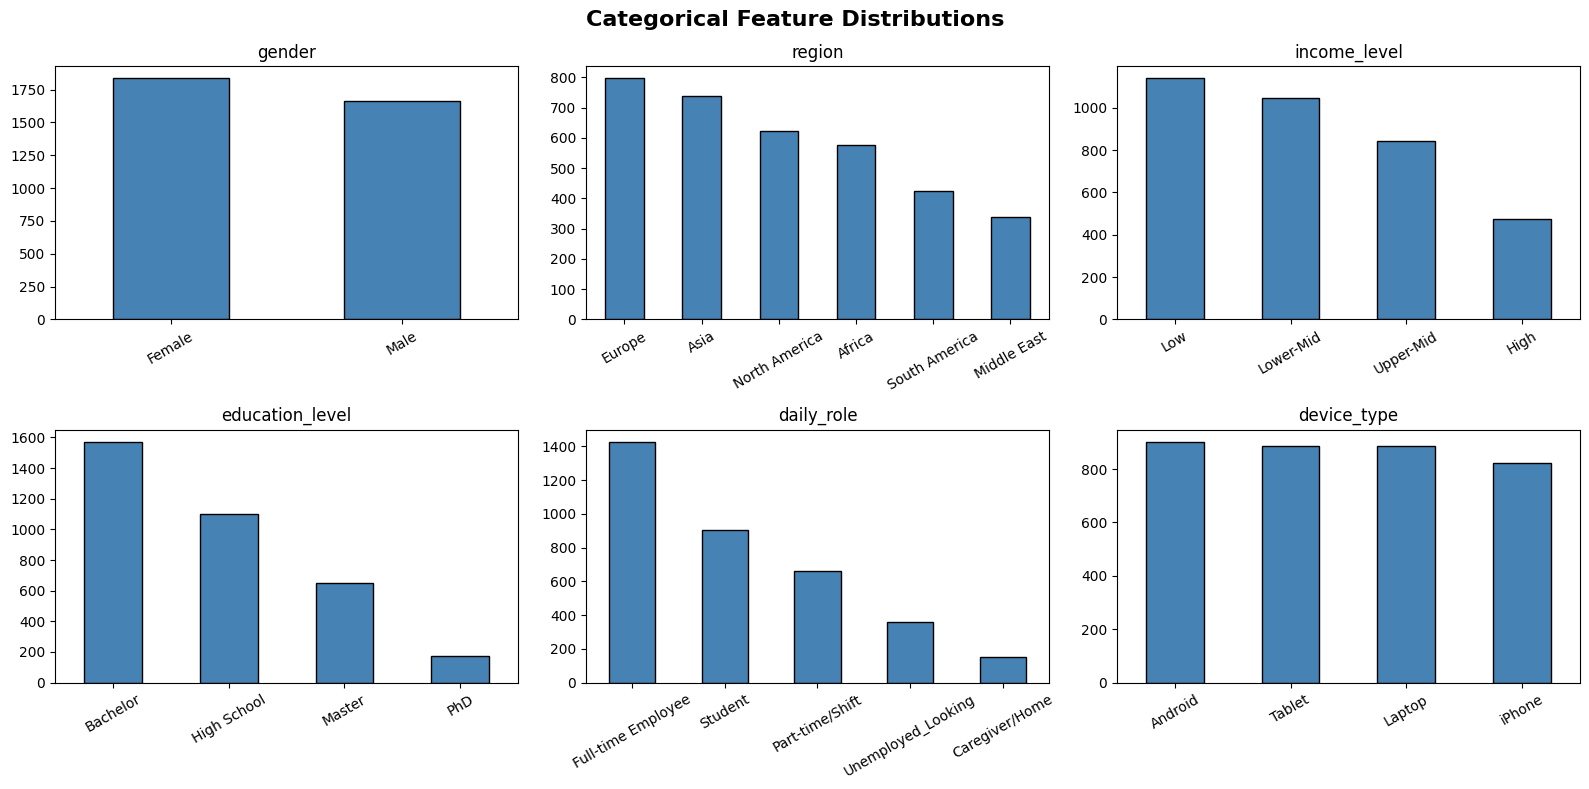

In [ ]:
# Value counts for each categorical column
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flatten(), cat_cols):
    df[col].value_counts().plot(kind='bar', ax=ax, color='steelblue', edgecolor='black')
    ax.set_title(col)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
plt.suptitle('Categorical Feature Distributions', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

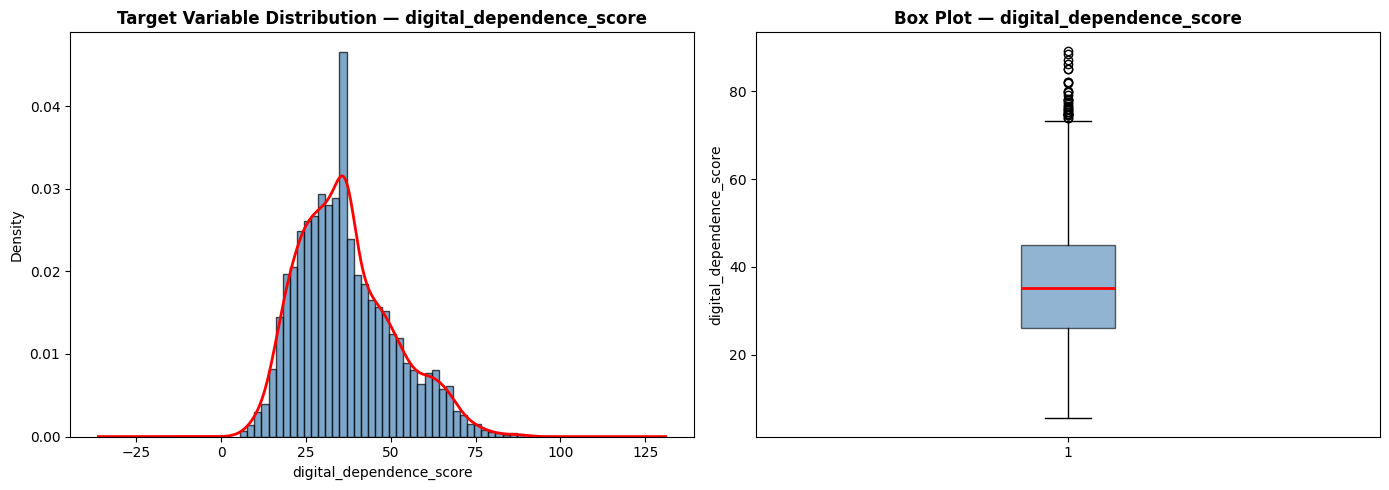

Target Variable Stats:
count    3500.000
mean       36.684
std        14.116
min         5.600
25%        26.200
50%        35.300
75%        45.100
max        89.200
Name: digital_dependence_score, dtype: float64


In [ ]:
# Target variable: digital_dependence_score
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram + KDE
axes[0].hist(df['digital_dependence_score'], bins=40, color='steelblue',
             edgecolor='black', density=True, alpha=0.7)
df['digital_dependence_score'].plot(kind='kde', ax=axes[0], color='red', linewidth=2)
axes[0].set_title('Target Variable Distribution — digital_dependence_score',
                  fontweight='bold')
axes[0].set_xlabel('digital_dependence_score')
axes[0].set_ylabel('Density')

# Box plot
axes[1].boxplot(df['digital_dependence_score'].dropna(), patch_artist=True,
                boxprops=dict(facecolor='steelblue', alpha=0.6),
                medianprops=dict(color='red', linewidth=2))
axes[1].set_title('Box Plot — digital_dependence_score', fontweight='bold')
axes[1].set_ylabel('digital_dependence_score')

plt.tight_layout()
plt.show()

print("Target Variable Stats:")
print(df['digital_dependence_score'].describe().round(3))

# **PREPROCESSING**

In [ ]:
# Convert categorical variables to numerical (one-hot encoding)
df_drop_ant = pd.get_dummies(df, columns=['gender', 'region', 'income_level', 'education_level', 'daily_role', 'device_type'])

# **Correlation matrix**

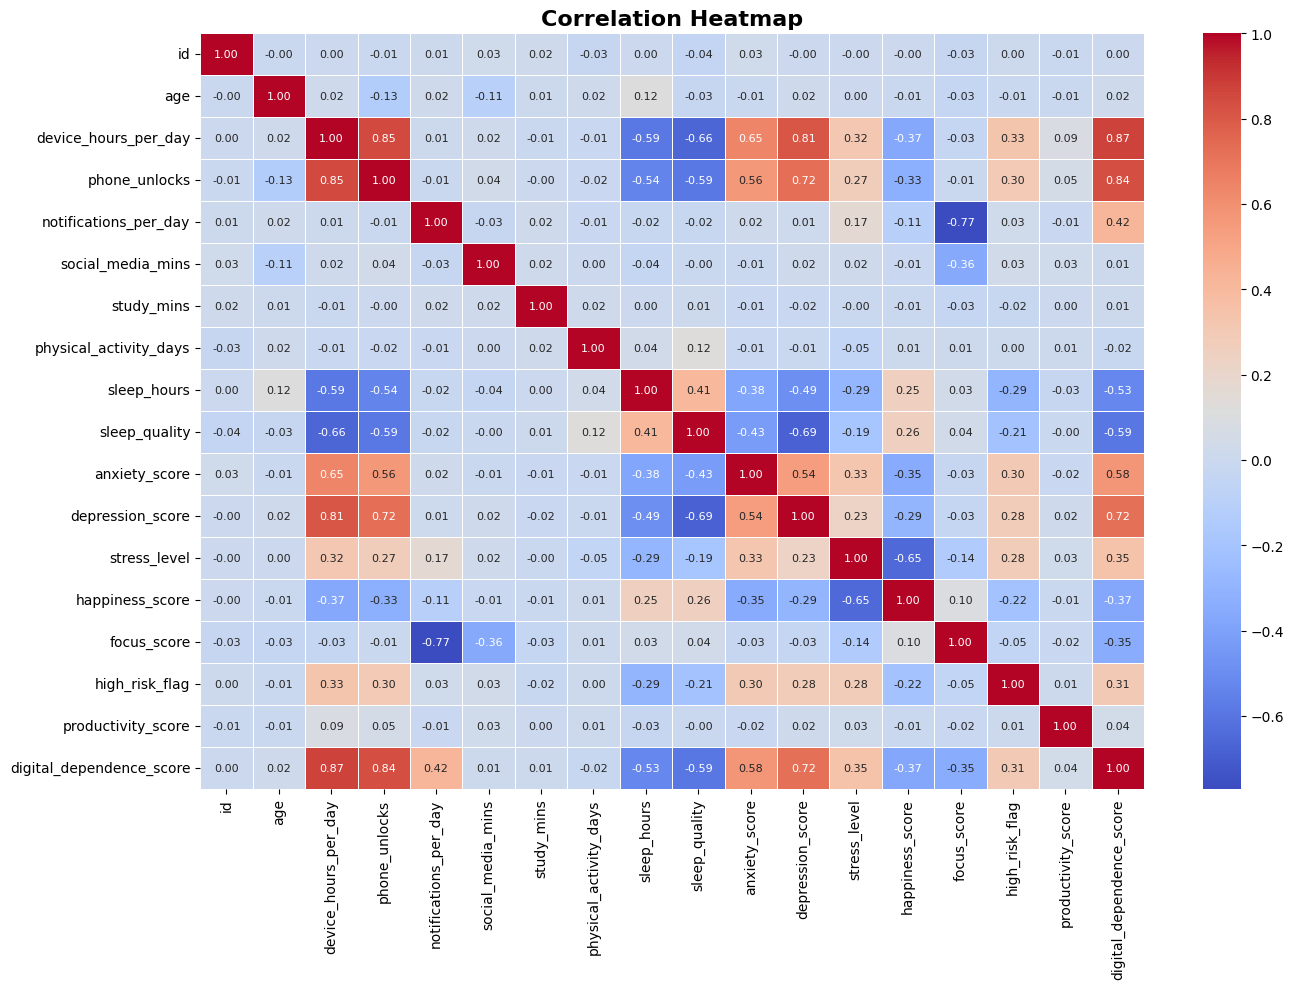

In [ ]:
plt.figure(figsize=(14, 10))
correlation_matrix = df.corr(numeric_only=True)
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    linewidths=0.5,
    annot_kws={"size": 8}
)
plt.title('Correlation Heatmap', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# **Class Imbalance Check**

In [ ]:
# Class distribution
print(df['high_risk_flag'].value_counts())
print()
print(df['high_risk_flag'].value_counts(normalize=True).round(4) * 100)

high_risk_flag
0    2795
1     705
Name: count, dtype: int64

high_risk_flag
0    79.86
1    20.14
Name: proportion, dtype: float64


Before SMOTE: Counter({0: 2795, 1: 705})
After SMOTE:  Counter({0: 2795, 1: 2795})


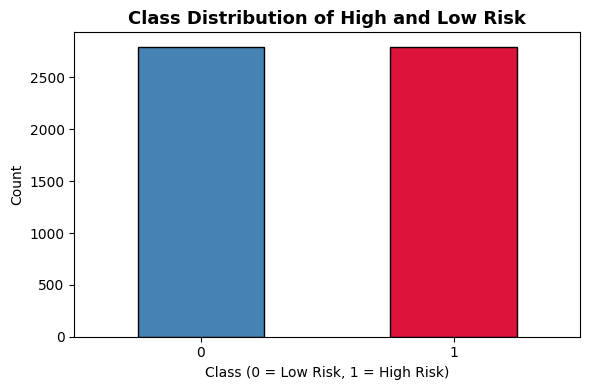

In [ ]:
from imblearn.over_sampling import SMOTE
from collections import Counter
from sklearn.preprocessing import LabelEncoder

# Prepare data for SMOTE by encoding categorical variables
X = df.drop(columns=['high_risk_flag', 'id'])
y = df['high_risk_flag']

# Label Encode objects
X_encoded = X.copy()
le = LabelEncoder()
for col in cat_cols:
    X_encoded[col] = le.fit_transform(X_encoded[col].astype(str))

# Apply SMOTE to oversample minority class
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_encoded, y)

print("Before SMOTE:", Counter(y))
print("After SMOTE: ", Counter(y_resampled))

# Plot new balanced distribution
pd.Series(y_resampled).value_counts().plot(kind='bar', color=['steelblue', 'crimson'],
                                            edgecolor='black', figsize=(6, 4))
plt.title('Class Distribution of High and Low Risk', fontsize=13, fontweight='bold')
plt.xlabel('Class (0 = Low Risk, 1 = High Risk)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

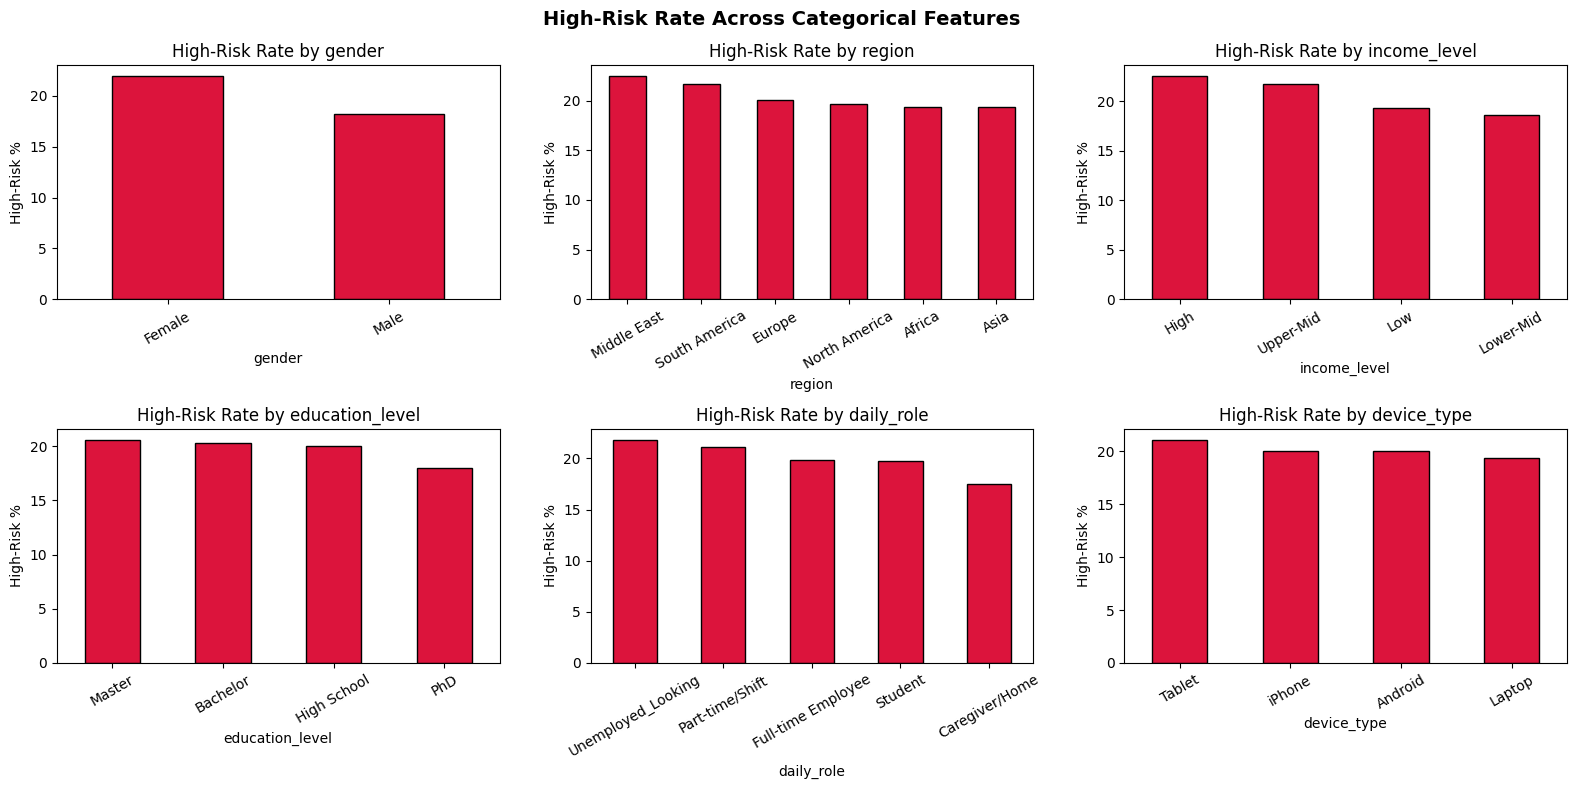

In [ ]:

# High-risk rate by each categorical column
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flatten(), cat_cols):
    df.groupby(col)['high_risk_flag'].mean().mul(100).sort_values(ascending=False).plot(
        kind='bar', ax=ax, color='crimson', edgecolor='black')
    ax.set_title(f'High-Risk Rate by {col}')
    ax.set_ylabel('High-Risk %')
    ax.tick_params(axis='x', rotation=30)
plt.suptitle('High-Risk Rate Across Categorical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Apply SMOTE to handle class imbalance
df_smote = df.copy()

# encode categoricals and fill missing for SMOTE
for col in cat_cols:
    df_smote[col] = LabelEncoder().fit_transform(df_smote[col])
df_smote = df_smote.fillna(df_smote.median(numeric_only=True))

X = df_smote.drop('high_risk_flag', axis=1)
y = df_smote['high_risk_flag']

sm = SMOTE(random_state=42)
X_resampled, y_resampled = sm.fit_resample(X, y)

print('Before SMOTE:', y.value_counts().to_dict())
print('After  SMOTE:', pd.Series(y_resampled).value_counts().to_dict())

Before SMOTE: {0: 2795, 1: 705}
After  SMOTE: {0: 2795, 1: 2795}


# **Outliner Treatment**

In [ ]:
# Count outliers per column using IQR method
outlier_summary = {}
for col in num_cols:
    s = df[col].dropna()
    Q1, Q3 = s.quantile(0.25), s.quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((s < lower) | (s > upper)).sum()
    outlier_summary[col] = {'outliers': n_out, 'lower_bound': round(lower, 2), 'upper_bound': round(upper, 2)}

outlier_df = pd.DataFrame(outlier_summary).T
print(outlier_df)

                          outliers  lower_bound  upper_bound
id                             0.0     -1748.50      5249.50
age                            0.0         1.50        53.50
device_hours_per_day          32.0        -1.56        15.58
phone_unlocks                 16.0       -40.50       323.50
notifications_per_day        189.0      -226.00       830.00
social_media_mins            238.0      -136.00       408.00
study_mins                    11.0      -139.50       344.50
physical_activity_days         0.0        -2.50         9.50
sleep_hours                   20.0         3.78        10.79
sleep_quality                  0.0        -0.12         5.31
anxiety_score                266.0        -3.27        16.11
depression_score               5.0        -9.50        26.50
stress_level                   0.0        -9.84        19.97
happiness_score                0.0        -3.35        16.25
focus_score                    0.0       -26.62       110.38
high_risk_flag          

In [ ]:
# Count outliers per column using Z-score method (|z| > 3)
z_outliers = {}
for col in num_cols:
    s = df[col].dropna()
    z = np.abs(stats.zscore(s))
    z_outliers[col] = (z > 3).sum()

print(pd.Series(z_outliers, name='Z-score outliers (|z|>3)').sort_values(ascending=False))

social_media_mins           105
notifications_per_day        96
anxiety_score                79
productivity_score           15
digital_dependence_score     13
study_mins                   11
sleep_hours                   8
depression_score              5
phone_unlocks                 3
device_hours_per_day          1
age                           0
id                            0
sleep_quality                 0
physical_activity_days        0
happiness_score               0
stress_level                  0
high_risk_flag                0
focus_score                   0
Name: Z-score outliers (|z|>3), dtype: int64


In [ ]:
# Apply IQR clipping to treat outliers
df_clean = df.copy()

for col in num_cols:
    s = df_clean[col].dropna()
    Q1, Q3 = s.quantile(0.25), s.quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    df_clean[col] = df_clean[col].clip(lower=lower, upper=upper)

print('Outlier treatment done — IQR clipping applied to all numerical columns.')

Outlier treatment done — IQR clipping applied to all numerical columns.


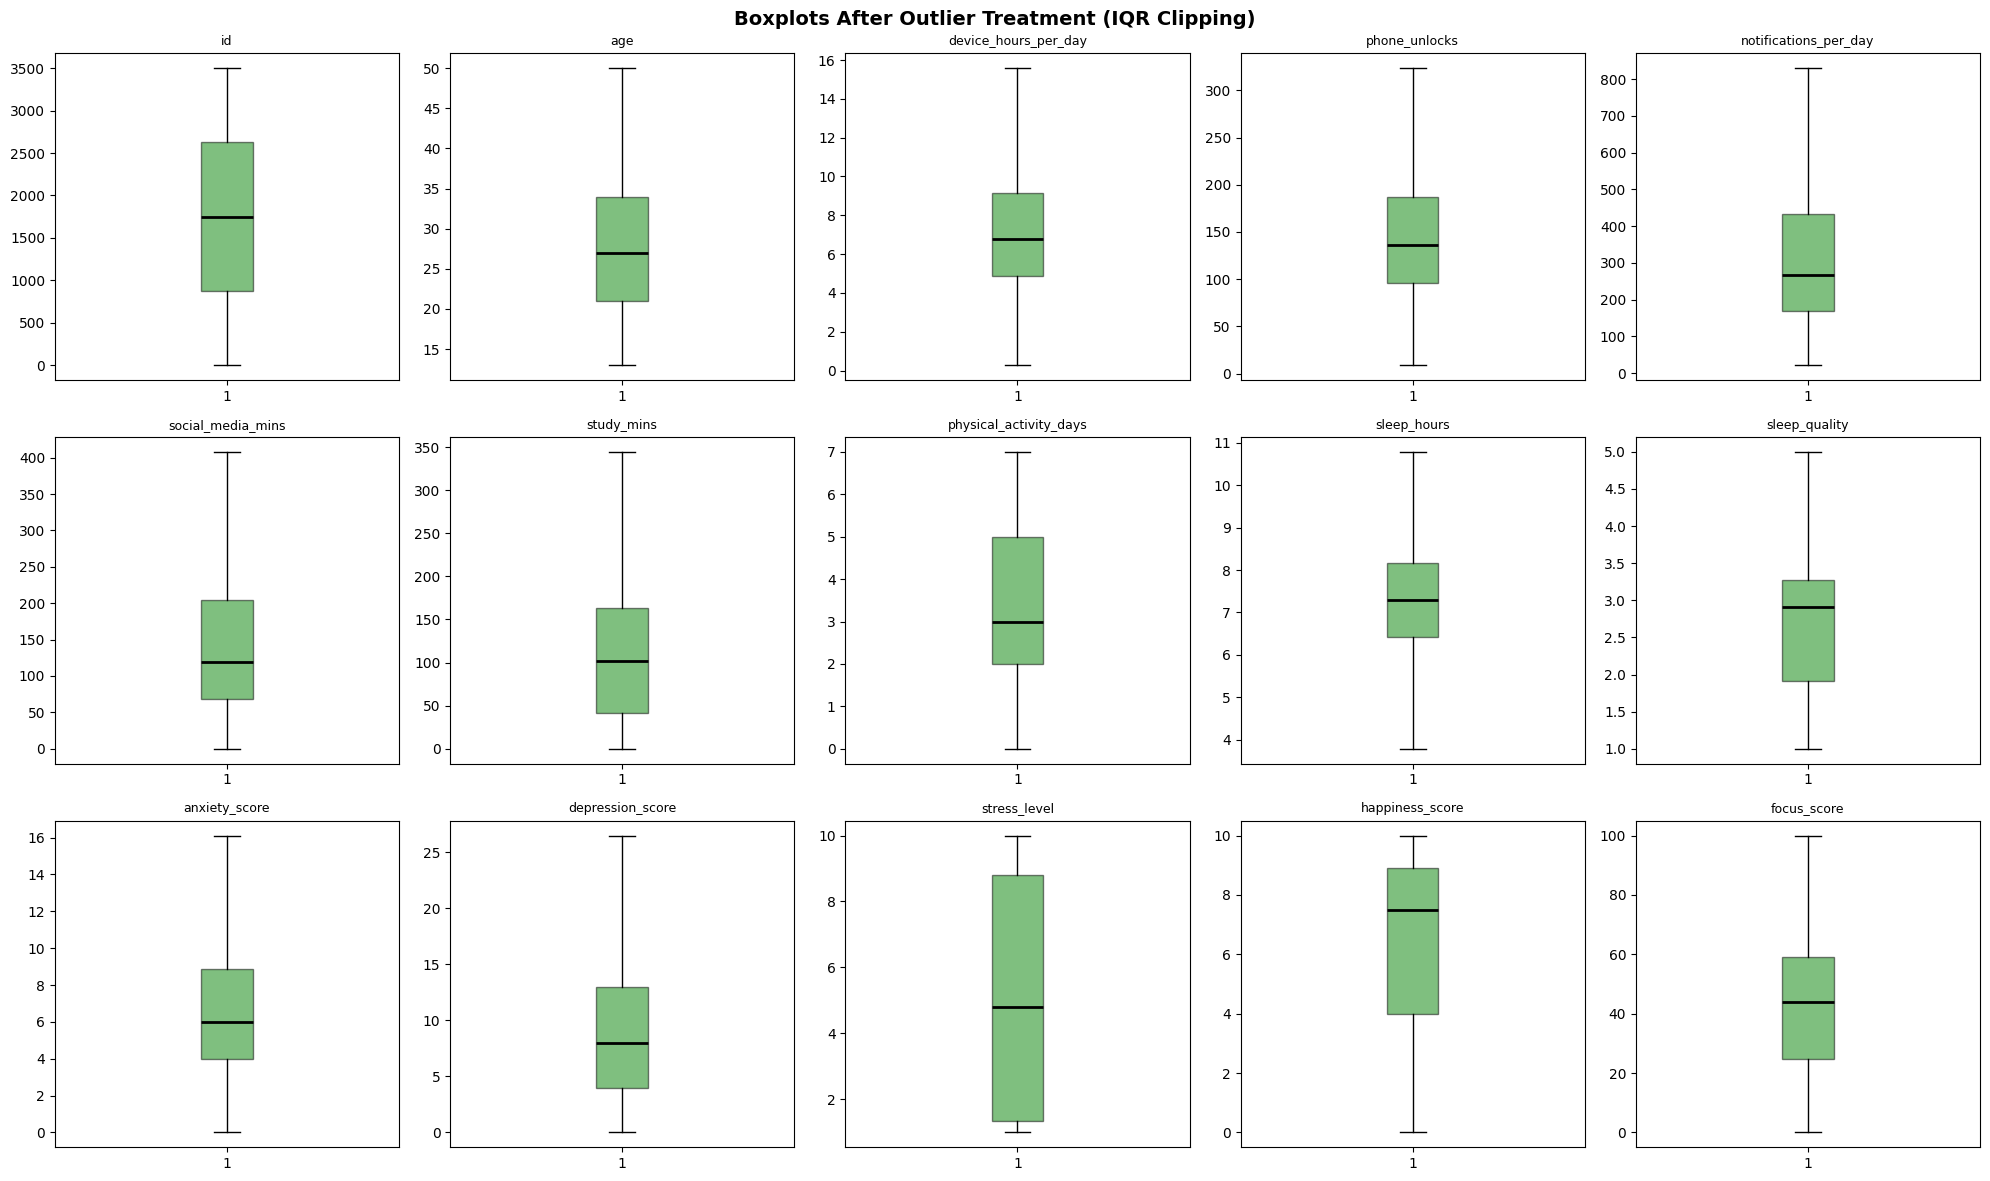

In [ ]:
# Boxplots of outlier treatment
fig, axes = plt.subplots(3, 5, figsize=(20, 12))
for ax, col in zip(axes.flatten(), num_cols):
    ax.boxplot(df_clean[col].dropna(), patch_artist=True,
               boxprops=dict(facecolor='green', alpha=0.5),
               medianprops=dict(color='black', linewidth=2),
               flierprops=dict(marker='o', color='orange', alpha=0.4))
    ax.set_title(col, fontsize=9)
for ax in axes.flatten()[len(num_cols):]:
    ax.set_visible(False)
plt.suptitle('Boxplots After Outlier Treatment (IQR Clipping)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

##  **FeatureEngineering**

In [ ]:
# Feature 1: Mental Health Index (wellbeing - distress)
df_fe = df_clean.copy()
df_fe['mental_health_index'] = (
    df_fe['happiness_score'] + df_fe['focus_score'] + df_fe['productivity_score']
    - df_fe['stress_level'] - df_fe['anxiety_score'] - df_fe['depression_score']
)

df_fe['mental_health_index'].describe()

,mental_health_index
count,3500.000000
mean,92.589691
std,29.006162
min,4.306101
25%,71.787417
50%,95.200812
75%,113.807915
max,172.300000


In [ ]:
# Feature 2: Sleep-Stress Ratio
df_fe['sleep_stress_ratio'] = df_fe['sleep_quality'] / (df_fe['stress_level'] + 0.01)

df_fe['sleep_stress_ratio'].describe()

,sleep_stress_ratio
count,3500.000000
mean,1.134444
std,1.183266
min,0.099900
25%,0.302766
50%,0.593542
75%,1.653203
max,4.950495


In [ ]:
# Feature 3: Notification Density (notifications per device hour)
df_fe['notification_density'] = df_fe['notifications_per_day'] / (df_fe['device_hours_per_day'] + 0.01)

df_fe['notification_density'].describe()

,notification_density
count,3500.000000
mean,55.328340
std,57.547350
min,1.678322
25%,23.166628
50%,40.220090
75%,68.836838
max,1373.469388


In [ ]:
# Feature 4: Age Group (binning)
df_fe['age_group'] = pd.cut(
    df_fe['age'],
    bins=[0, 24, 34, 44, 65],
    labels=['(<=24)', '(25-34)', '(35-44)', '(45+)']
)

df_fe['age_group'].value_counts()

,count
age_group,
(<=24),1491
(25-34),1218
(35-44),550
(45+),241


In [ ]:
# Feature 5: Heavy User flag
df_fe['is_heavy_user'] = (df_fe['device_hours_per_day'] > 10).astype(int)

df_fe['is_heavy_user'].value_counts()

,count
is_heavy_user,
0,2819
1,681


In [ ]:
# Label encode all categorical columns
df_fe_encoded = df_fe.copy()
le = LabelEncoder()

encode_cols = cat_cols + ['age_group']
for col in encode_cols:
    df_fe_encoded[col] = le.fit_transform(df_fe_encoded[col].astype(str))

print('Encoded columns:', encode_cols)

Encoded columns: ['gender', 'region', 'income_level', 'education_level', 'daily_role', 'device_type', 'age_group']


In [ ]:
# View final dataframe
print('Final shape:', df_fe_encoded.shape)
df_fe_encoded.head()

Final shape: (3500, 29)


,id,age,gender,region,income_level,education_level,daily_role,device_hours_per_day,phone_unlocks,notifications_per_day,...,focus_score,high_risk_flag,device_type,productivity_score,digital_dependence_score,mental_health_index,sleep_stress_ratio,notification_density,age_group,is_heavy_user
0,1,40,0,1,0,1,2,3.54,45.0,561,...,23.0,0,0,70.000000,25.700000,79.480060,0.507872,158.028169,1,0
1,2,27,1,0,2,2,1,5.65,100.0,393,...,35.0,0,1,64.000000,30.100000,94.973074,0.702973,69.434629,0,0
2,3,31,1,4,2,0,1,8.87,181.0,231,...,15.0,0,0,65.299301,40.600000,74.470162,2.007598,26.013514,0,0
3,4,41,0,3,1,2,0,4.05,94.0,268,...,28.0,0,2,80.000000,36.684152,94.711131,0.618816,66.009852,1,0
4,5,26,0,2,2,0,1,13.07,199.0,91,...,70.0,0,0,65.299301,48.400000,108.022418,0.294552,6.957187,0,1


# **Spliting Data**

In [ ]:
from sklearn.preprocessing import StandardScaler

# Using the feature engineered dataframe for better results
X_final = df_fe_encoded.drop(['digital_dependence_score', 'id', 'age_group'], axis=1)
y_final = df_fe_encoded['digital_dependence_score']

# Split using the same random state to ensure feature/target alignment
# We capture the feature splits but will use the global y_train/y_test for the targets
X_train_nn, X_test_nn, _, _ = train_test_split(X_final, y_final, test_size=0.2, random_state=42)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_nn)
X_test_scaled = scaler.transform(X_test_nn)

print('Data scaled successfully for Neural Networks.')

Data scaled successfully for Neural Networks.


In [ ]:
# Split the data into 80-20 train-test split

X = df_drop_ant.drop(['digital_dependence_score',"id"], axis=1) # features
y = df_drop_ant['digital_dependence_score'] # target column

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# display the shapes

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (2800, 41)
X_test shape: (700, 41)
y_train shape: (2800,)
y_test shape: (700,)


In [ ]:
# Use the SMOTE-resampled data for model training
X_train_sm, X_test_sm, y_train_sm, y_test_sm = train_test_split(
    X_resampled, y_resampled, test_size=0.2, random_state=42
)

print("SMOTE X_train shape:", X_train_sm.shape)
print("SMOTE X_test shape:", X_test_sm.shape)

SMOTE X_train shape: (4472, 23)
SMOTE X_test shape: (1118, 23)


# **Random forest**

Random Forest Regressor Mean Squared Error: 8.891139507409195
Random Forest Regressor R-squared: 0.9556134328217742


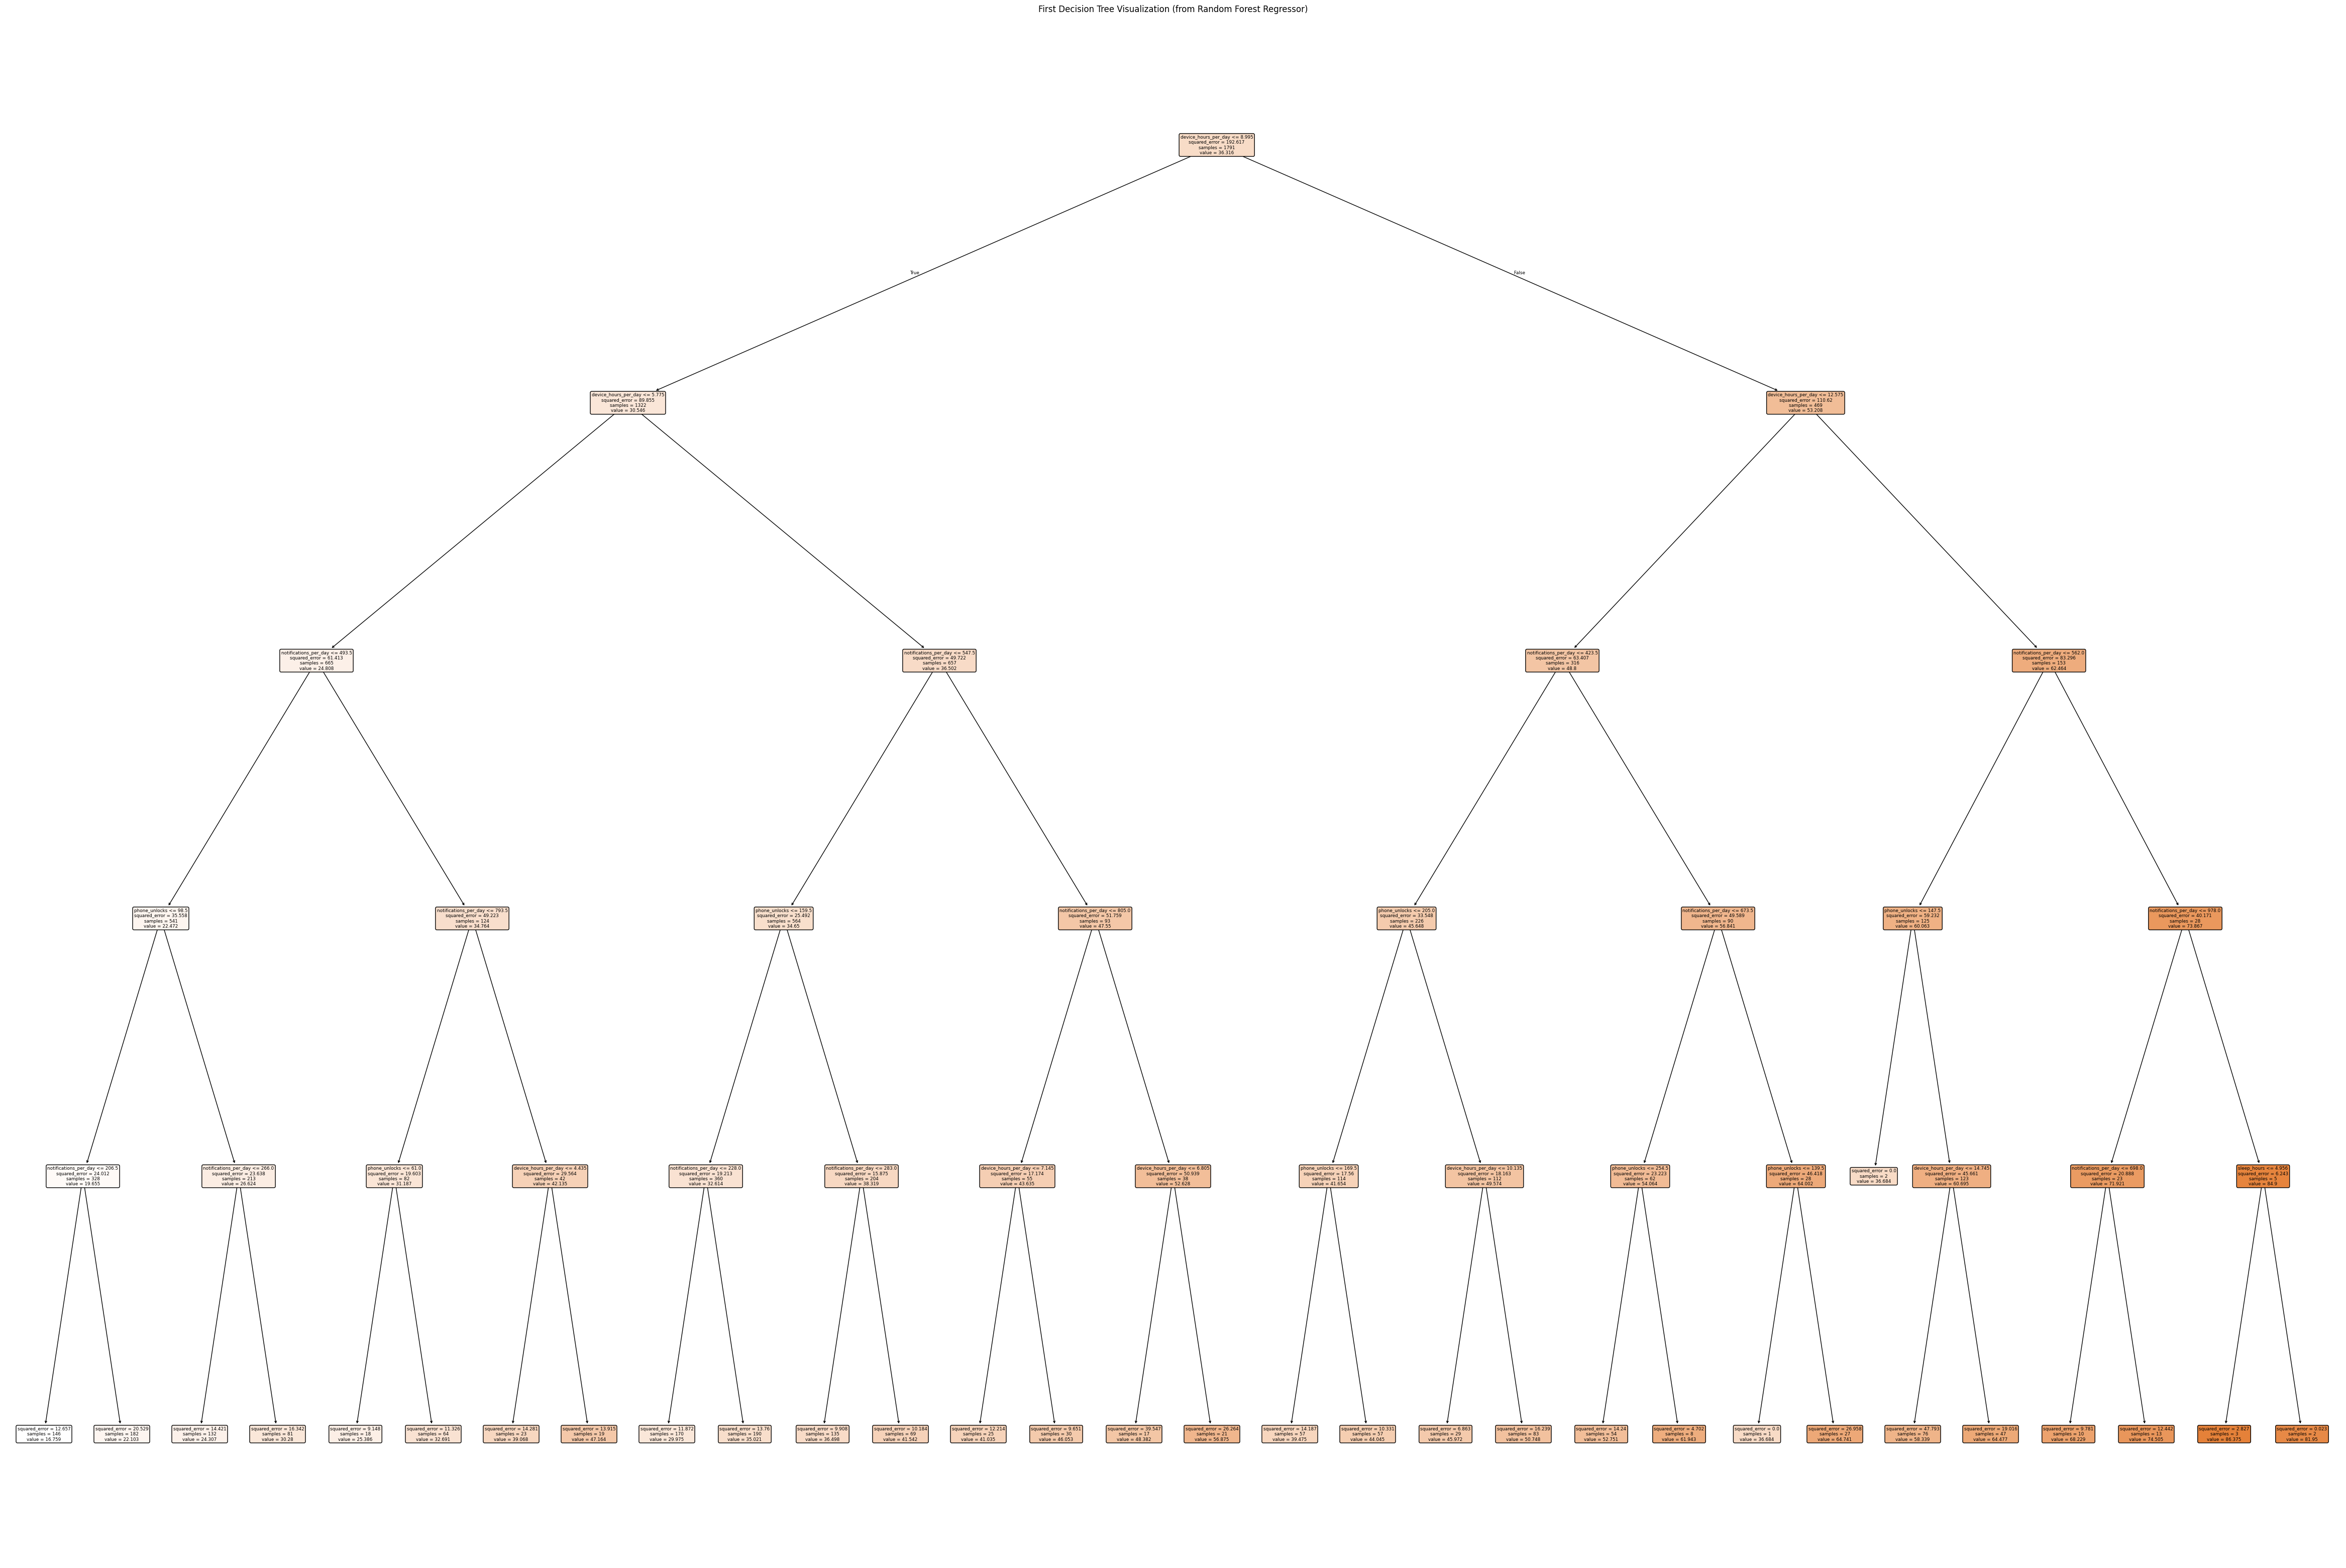

Random forest Mean Squared Error: 8.891139507409195
Random forest  R-squared: 0.9556134328217742


In [ ]:
random_forest_model = RandomForestRegressor(n_estimators=100, max_depth = 5, bootstrap=True, random_state=42)
random_forest_model.fit(X_train, y_train)

# Predictions on the test set
y_pred_rf = random_forest_model.predict(X_test)


print("Random Forest Regressor Mean Squared Error:", mean_squared_error(y_test, y_pred_rf))
print("Random Forest Regressor R-squared:", r2_score(y_test, y_pred_rf))


plt.figure(figsize=(60, 40))

plot_tree(random_forest_model.estimators_[0], feature_names=X.columns, filled=True, rounded=True)
plt.title('First Decision Tree Visualization (from Random Forest Regressor)')
plt.show()

print("Random forest Mean Squared Error:", mean_squared_error(y_test,y_pred_rf))
print("Random forest  R-squared:", r2_score(y_test, y_pred_rf))

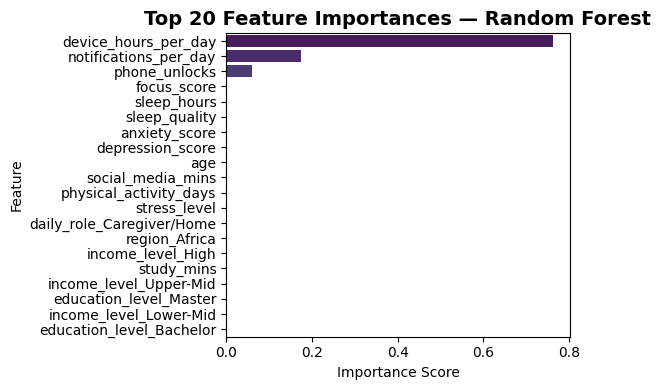

In [ ]:
# Feature Importance from Random Forest
importances = random_forest_model.feature_importances_
feature_names = X.columns
feat_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_imp_df = feat_imp_df.sort_values('Importance', ascending=False).head(20)

plt.figure(figsize=(6, 4))
sns.barplot(data=feat_imp_df, x='Importance', y='Feature', palette='viridis')
plt.title('Top 20 Feature Importances — Random Forest', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# **Adaboost**

In [ ]:
abr = AdaBoostRegressor(n_estimators=50, learning_rate=0.5, random_state=42)
model = abr.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("AdaBoost Regressor Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("AdaBoost Regressor R-squared:", r2_score(y_test, y_pred))

AdaBoost Regressor Mean Squared Error: 19.129816677538795
AdaBoost Regressor R-squared: 0.9044996547003745


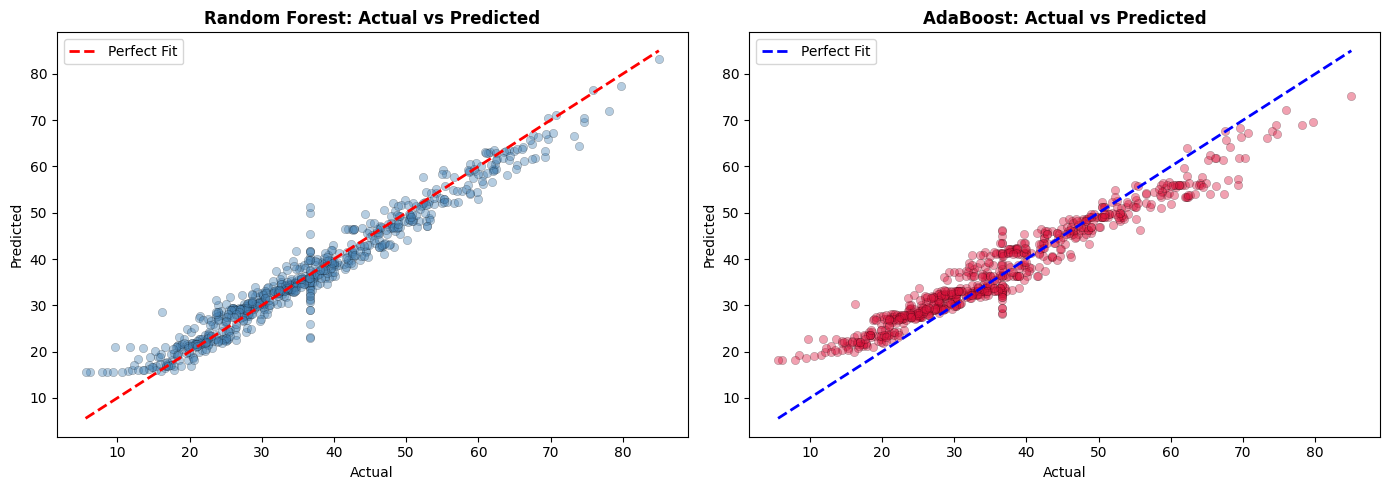

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Random Forest
axes[0].scatter(y_test, y_pred_rf, alpha=0.4, color='steelblue', edgecolors='k', linewidths=0.3)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Fit')
axes[0].set_title('Random Forest: Actual vs Predicted', fontweight='bold')
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')
axes[0].legend()

# AdaBoost
axes[1].scatter(y_test, y_pred, alpha=0.4, color='crimson', edgecolors='k', linewidths=0.3)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'b--', lw=2, label='Perfect Fit')
axes[1].set_title('AdaBoost: Actual vs Predicted', fontweight='bold')
axes[1].set_xlabel('Actual')
axes[1].set_ylabel('Predicted')
axes[1].legend()

plt.tight_layout()
plt.show()

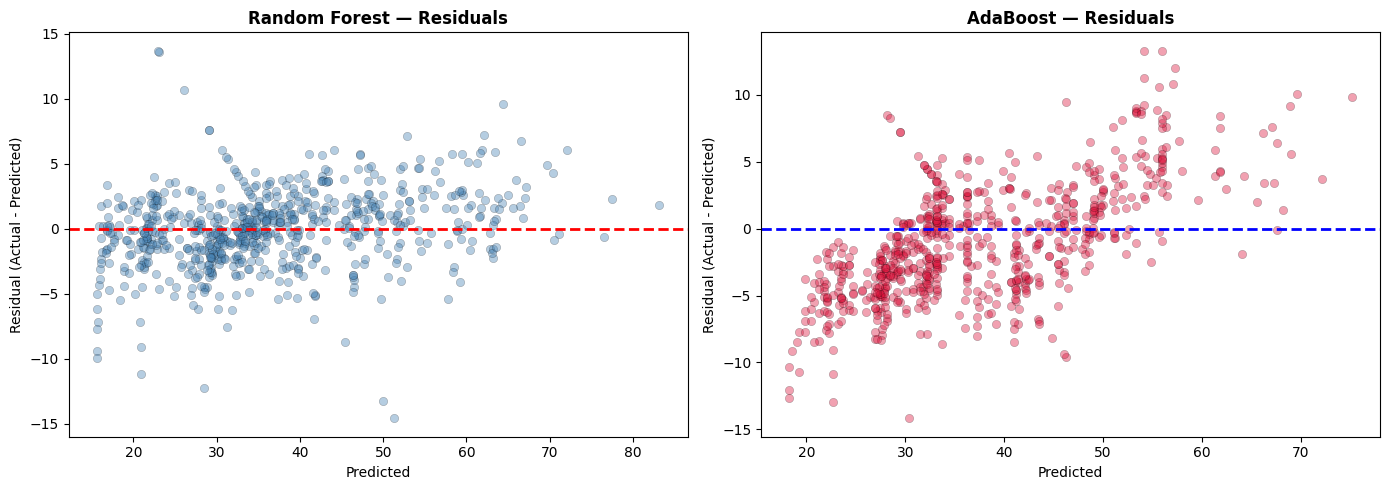

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

residuals_rf  = y_test - y_pred_rf
residuals_ada = y_test - y_pred

axes[0].scatter(y_pred_rf, residuals_rf, alpha=0.4, color='steelblue', edgecolors='k', linewidths=0.3)
axes[0].axhline(0, color='red', linestyle='--', lw=2)
axes[0].set_title('Random Forest — Residuals', fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Residual (Actual - Predicted)')

axes[1].scatter(y_pred, residuals_ada, alpha=0.4, color='crimson', edgecolors='k', linewidths=0.3)
axes[1].axhline(0, color='blue', linestyle='--', lw=2)
axes[1].set_title('AdaBoost — Residuals', fontweight='bold')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Residual (Actual - Predicted)')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import cross_val_score

# Cross-validation (5-fold, scoring R²)
cv_rf  = cross_val_score(random_forest_model, X, y, cv=5, scoring='r2')
cv_ada = cross_val_score(abr, X, y, cv=5, scoring='r2')

print("Random Forest  — CV R² scores:", cv_rf.round(4))
print("Random Forest  — Mean CV R²:", cv_rf.mean().round(4), "| Std:", cv_rf.std().round(4))
print()
print("AdaBoost       — CV R² scores:", cv_ada.round(4))
print("AdaBoost       — Mean CV R²:", cv_ada.mean().round(4), "| Std:", cv_ada.std().round(4))

Random Forest  — CV R² scores: [0.9423 0.9486 0.9393 0.9437 0.9468]
Random Forest  — Mean CV R²: 0.9441 | Std: 0.0033

AdaBoost       — CV R² scores: [0.8987 0.8993 0.8969 0.9049 0.8984]
AdaBoost       — Mean CV R²: 0.8996 | Std: 0.0027


       MODEL COMPARISON SUMMARY
               MSE (Test)  R² (Test)  Mean CV R²  CV R² Std
Model                                                      
Random Forest      8.8911     0.9556      0.9441     0.0033
AdaBoost          19.1298     0.9045      0.8996     0.0027


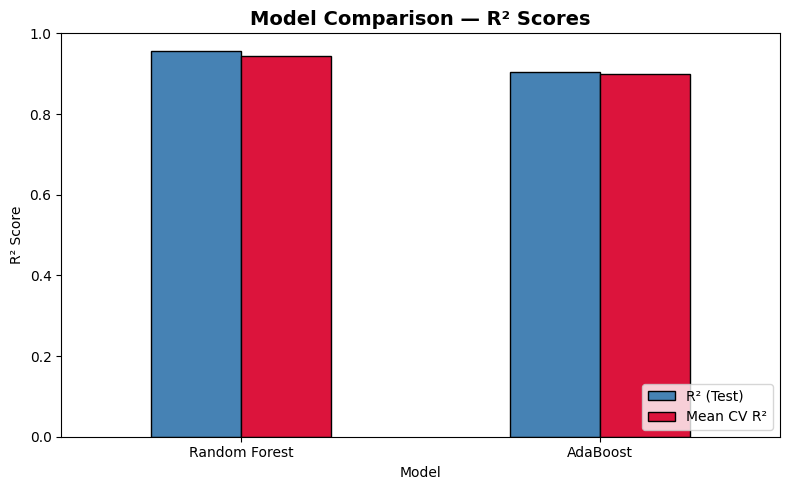

In [ ]:
# Final Model Comparison Table
comparison = pd.DataFrame({
    'Model': ['Random Forest', 'AdaBoost'],
    'MSE (Test)': [
        mean_squared_error(y_test, y_pred_rf),
        mean_squared_error(y_test, y_pred)
    ],
    'R² (Test)': [
        r2_score(y_test, y_pred_rf),
        r2_score(y_test, y_pred)
    ],
    'Mean CV R²': [cv_rf.mean(), cv_ada.mean()],
    'CV R² Std': [cv_rf.std(), cv_ada.std()]
}).set_index('Model').round(4)

print("=" * 55)
print("       MODEL COMPARISON SUMMARY")
print("=" * 55)
print(comparison.to_string())
print("=" * 55)

# Visual bar chart of R² scores
comparison[['R² (Test)', 'Mean CV R²']].plot(
    kind='bar', figsize=(8, 5), color=['steelblue', 'crimson'],
    edgecolor='black', rot=0
)
plt.title('Model Comparison — R² Scores', fontsize=14, fontweight='bold')
plt.ylabel('R² Score')
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Version 1: Scikit-Learn Multi-layer Perceptron (MLP)
This is a standard feed-forward neural network for regression tasks.

In [ ]:
from sklearn.neural_network import MLPRegressor

mlp_v1 = MLPRegressor(hidden_layer_sizes=(128, 64),
                      activation='relu',
                      solver='adam',
                      max_iter=500,
                      random_state=42)

mlp_v1.fit(X_train_scaled, y_train)
y_pred_v1 = mlp_v1.predict(X_test_scaled)

print(f"MLP V1 R2 Score: {r2_score(y_test, y_pred_v1):.4f}")

MLP V1 R2 Score: 0.9416


### Version 2: Keras/TensorFlow Deep Neural Network
This version allows for more complex architectures and better control over the training process.

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

model_v2 = models.Sequential([
    layers.Dense(128, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)
])

model_v2.compile(optimizer='adam', loss='mse')

history = model_v2.fit(X_train_scaled, y_train,
                    validation_split=0.2,
                    epochs=50,
                    batch_size=32,
                    verbose=0)

y_pred_v2 = model_v2.predict(X_test_scaled).flatten()
print(f"Keras DNN R2 Score: {r2_score(y_test, y_pred_v2):.4f}")

22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Keras DNN R2 Score: 0.9598


# **Explainable AI(XAI)**

**Shape for Random Forest**

In [ ]:
# Ensure JS is initialized for plots
shap.initjs()

# The issue often arises from non-float dtypes in the training set features.
# We ensure the background sample and test set are float64.
background_rf = shap.sample(X_train, 100, random_state=42).astype(float)
X_test_float = X_test.astype(float)

# Re-initialize the TreeExplainer with explicit float data
explainer_rf = shap.TreeExplainer(
    random_forest_model,
    data=background_rf,
    feature_perturbation='interventional'
)

# Compute SHAP values using the float-casted test set
shap_values_rf = explainer_rf.shap_values(X_test_float)

print("SHAP values computed successfully.")
print("SHAP values shape (RF):", shap_values_rf.shape)

SHAP values computed successfully.
SHAP values shape (RF): (700, 41)


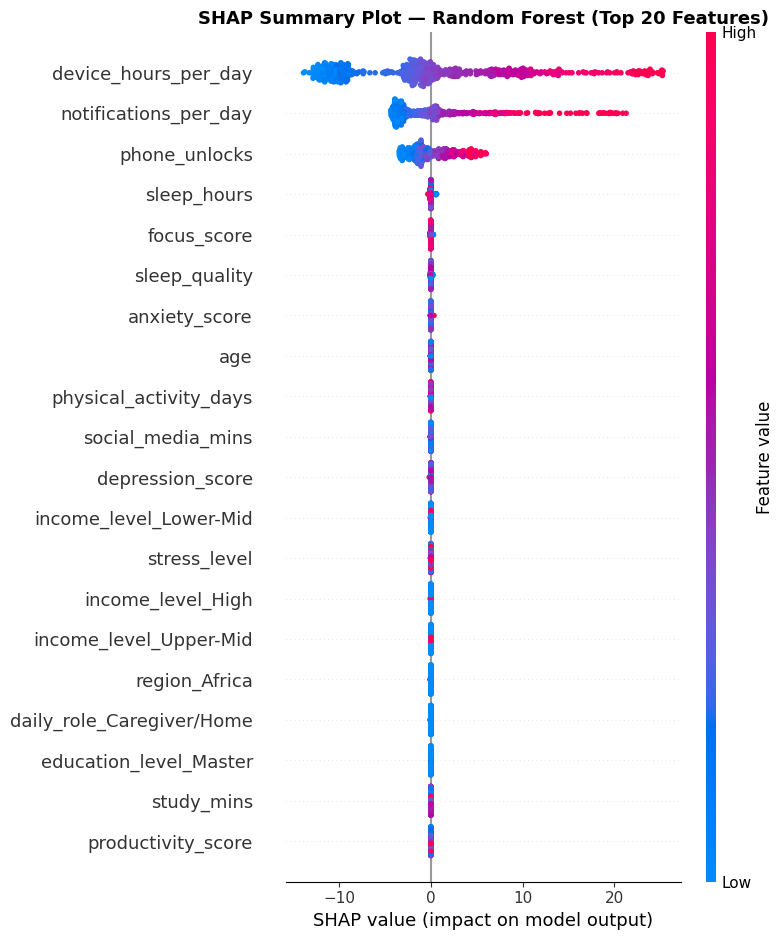

In [ ]:
# ── 1b. Global Explanation — SHAP Summary Beeswarm Plot (Random Forest) ────
plt.figure()
shap.summary_plot(
    shap_values_rf,
    X_test,
    feature_names=X_test.columns.tolist(),
    plot_type='dot',        # beeswarm
    max_display=20,
    show=False
)
plt.title('SHAP Summary Plot — Random Forest (Top 20 Features)',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

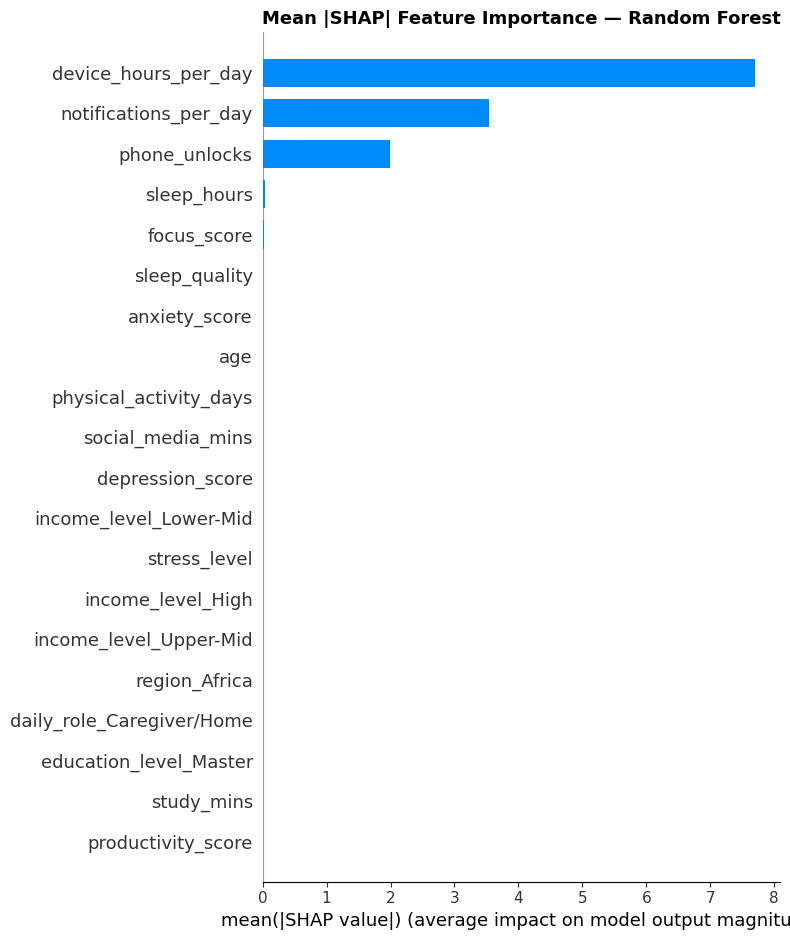

In [ ]:
# ── 1c. Global Explanation — SHAP Mean Absolute Bar Chart (Random Forest) ──
plt.figure()
shap.summary_plot(
    shap_values_rf,
    X_test,
    feature_names=X_test.columns.tolist(),
    plot_type='bar',
    max_display=20,
    show=False
)
plt.title('Mean |SHAP| Feature Importance — Random Forest',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

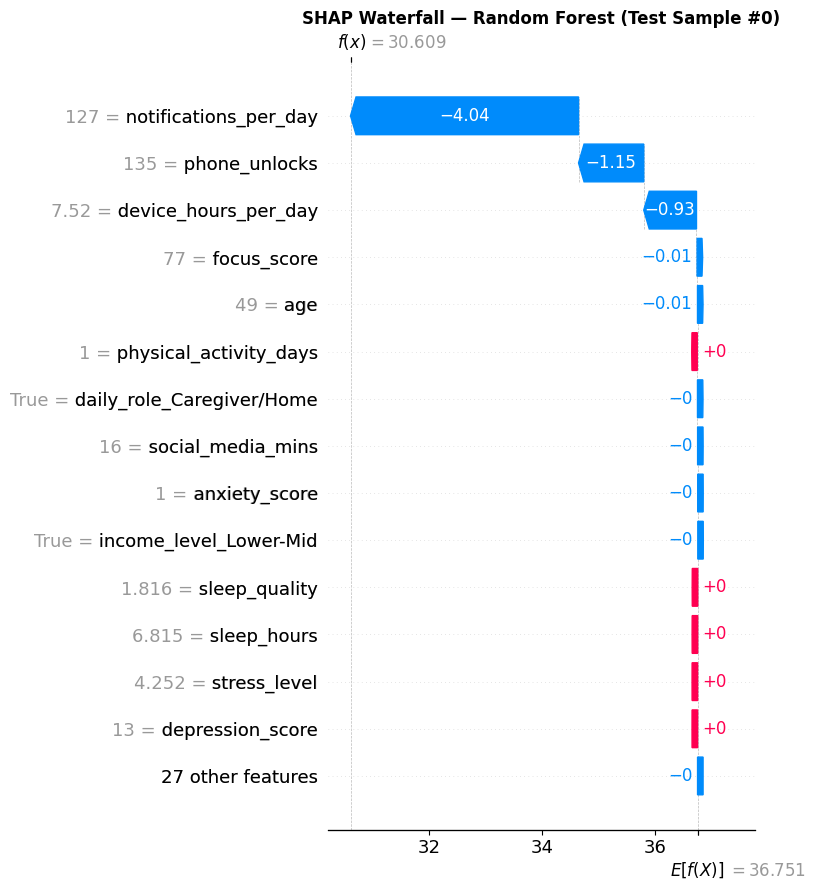

Actual value    : 32.6000
Predicted value : 30.6092


In [ ]:
# ── 1d. Local Explanation — SHAP Waterfall Plot for a single prediction ────
# Explain the first test instance
idx = 0

explainer_rf_exp = shap.TreeExplainer(random_forest_model)
shap_exp_rf      = explainer_rf_exp(X_test.iloc[[idx]])

plt.figure()
shap.plots.waterfall(shap_exp_rf[0], max_display=15, show=False)
plt.title(f'SHAP Waterfall — Random Forest (Test Sample #{idx})',
          fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Actual value    : {y_test.iloc[idx]:.4f}")
print(f"Predicted value : {y_pred_rf[idx]:.4f}")

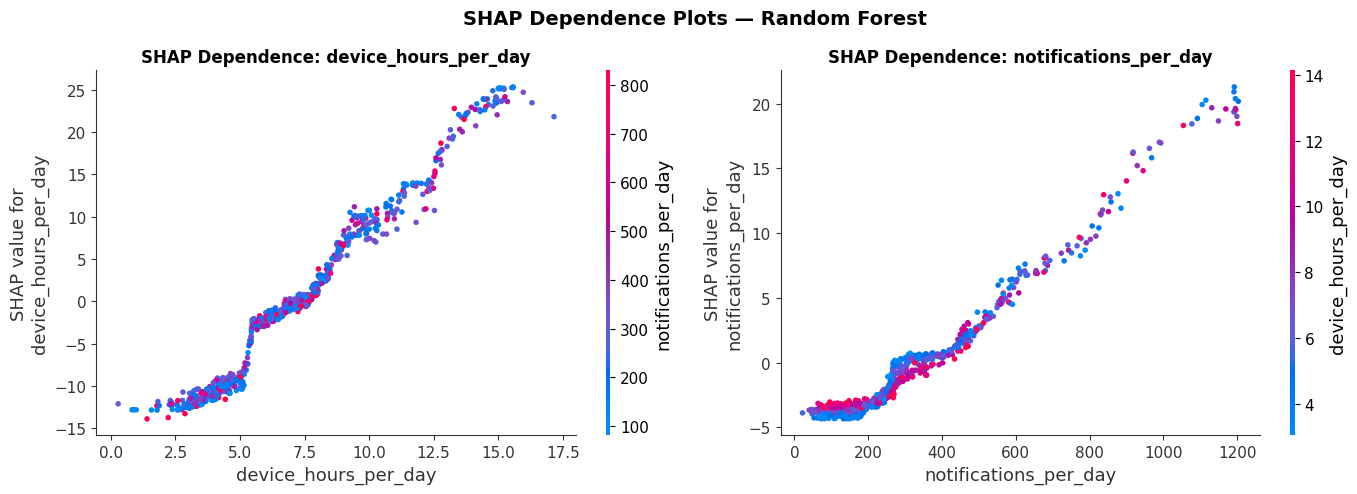

In [ ]:
# ── 1f. SHAP Dependence Plot — top two features ─────────────────────────────
# Find the top feature by mean absolute SHAP
mean_shap_rf = np.abs(shap_values_rf).mean(axis=0)
top2_idx     = np.argsort(mean_shap_rf)[::-1][:2]
top_feat1    = X_test.columns[top2_idx[0]]
top_feat2    = X_test.columns[top2_idx[1]]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

shap.dependence_plot(
    top_feat1,
    shap_values_rf,
    X_test,
    interaction_index=top_feat2,
    ax=axes[0], show=False
)
axes[0].set_title(f'SHAP Dependence: {top_feat1}', fontweight='bold')

shap.dependence_plot(
    top_feat2,
    shap_values_rf,
    X_test,
    interaction_index=top_feat1,
    ax=axes[1], show=False
)
axes[1].set_title(f'SHAP Dependence: {top_feat2}', fontweight='bold')

plt.suptitle('SHAP Dependence Plots — Random Forest',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Shap for AdaBoost**

In [ ]:
# ── 2a. SHAP KernelExplainer — AdaBoost ─────────────────────────────────────
# Use a small representative background sample for KernelExplainer
background_ada = shap.sample(X_train, 20, random_state=42)

# Use the model's predict method
explainer_ada = shap.KernelExplainer(abr.predict, background_ada)

# Compute SHAP values for a subset of the test set (KernelExplainer is computationally intensive)
X_test_subset = X_test.iloc[:50]
shap_values_ada = explainer_ada.shap_values(X_test_subset)

print("SHAP values computed successfully for AdaBoost using KernelExplainer.")
print("SHAP values shape (AdaBoost):", shap_values_ada.shape)

  0%|          | 0/50 [00:00<?, ?it/s]

SHAP values computed successfully for AdaBoost using KernelExplainer.
SHAP values shape (AdaBoost): (50, 41)


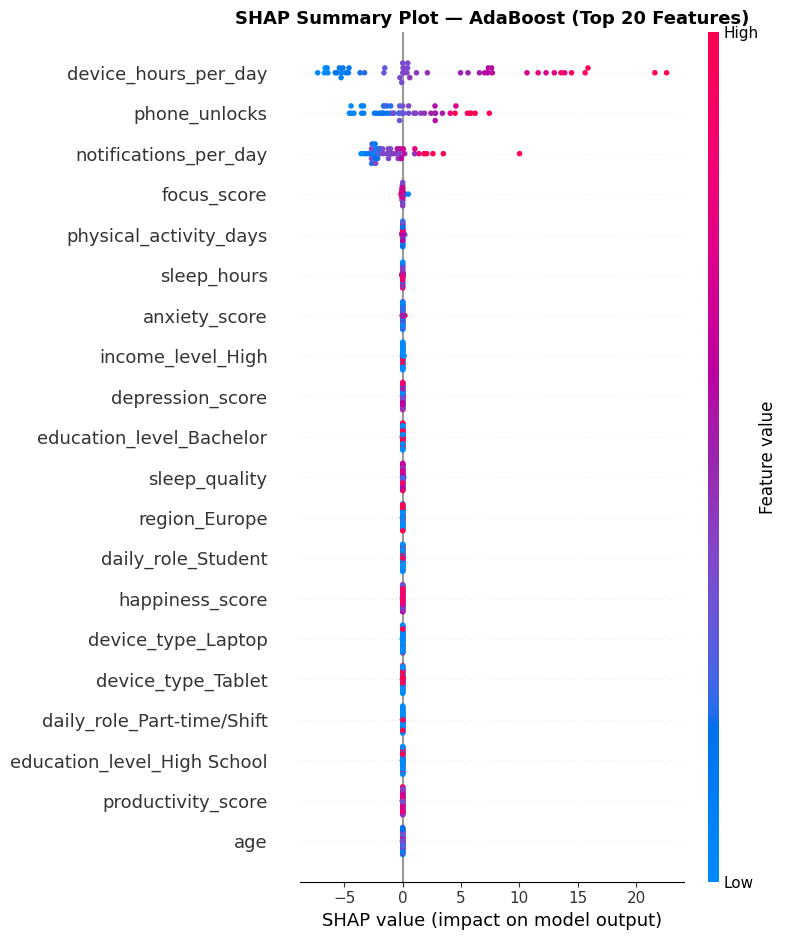

In [ ]:
# ── 2b. Global Explanation — SHAP Beeswarm (AdaBoost) ─────────────────────
plt.figure()
shap.summary_plot(
    shap_values_ada,
    X_test_subset, # Use the matching subset
    feature_names=X_test.columns.tolist(),
    plot_type='dot',
    max_display=20,
    show=False
)
plt.title('SHAP Summary Plot — AdaBoost (Top 20 Features)',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

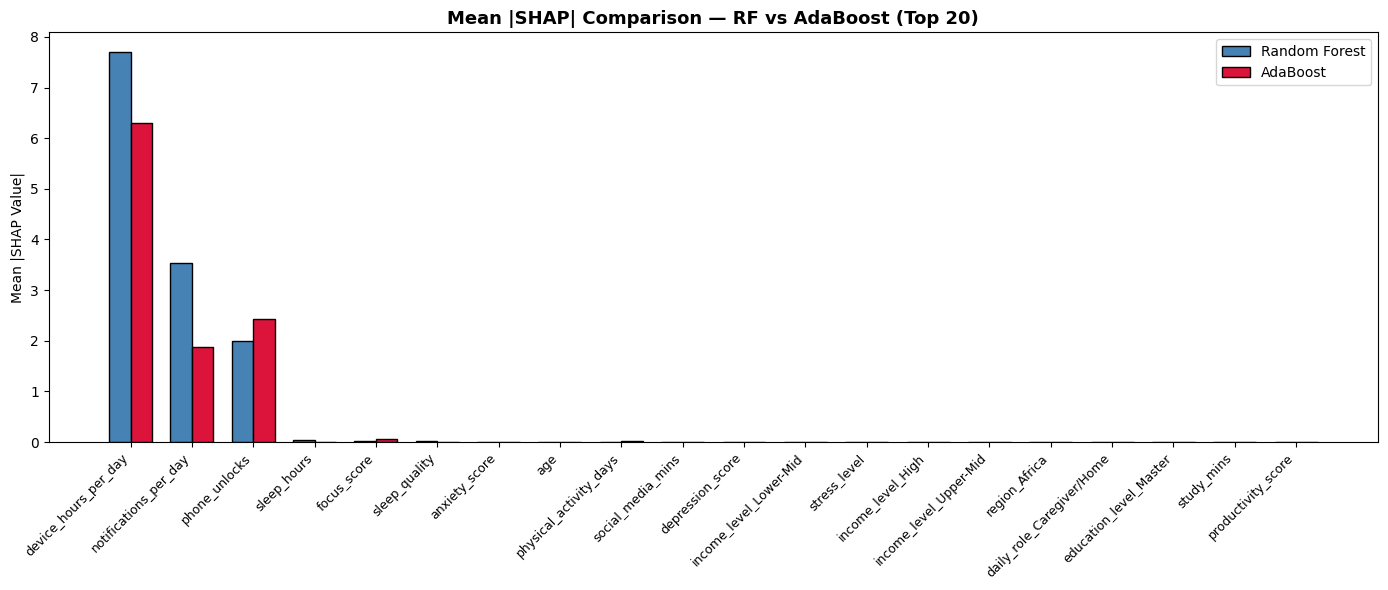

In [ ]:
# ── 2c. Side-by-side Mean |SHAP| comparison: RF vs AdaBoost ───────────────
mean_shap_rf_vals  = np.abs(shap_values_rf).mean(axis=0)
mean_shap_ada_vals = np.abs(shap_values_ada).mean(axis=0)

shap_compare = pd.DataFrame({
    'Feature'  : X_test.columns,
    'RF SHAP'  : mean_shap_rf_vals,
    'Ada SHAP' : mean_shap_ada_vals
}).sort_values('RF SHAP', ascending=False).head(20)

x = np.arange(len(shap_compare))
width = 0.35

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(x - width/2, shap_compare['RF SHAP'],  width, label='Random Forest', color='steelblue', edgecolor='black')
ax.bar(x + width/2, shap_compare['Ada SHAP'], width, label='AdaBoost',      color='crimson',   edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(shap_compare['Feature'], rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Mean |SHAP Value|')
ax.set_title('Mean |SHAP| Comparison — RF vs AdaBoost (Top 20)',
             fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

**LIME**

In [ ]:
# ── 3a. Build LIME Explainer ───────────────────────────────────────────────
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data  = X_train.values,
    feature_names  = X_train.columns.tolist(),
    mode           = 'regression',
    random_state   = 42,
    discretize_continuous = True
)

print("LIME explainer ready.")
print(f"Number of features: {X_train.shape[1]}")

LIME explainer ready.
Number of features: 41


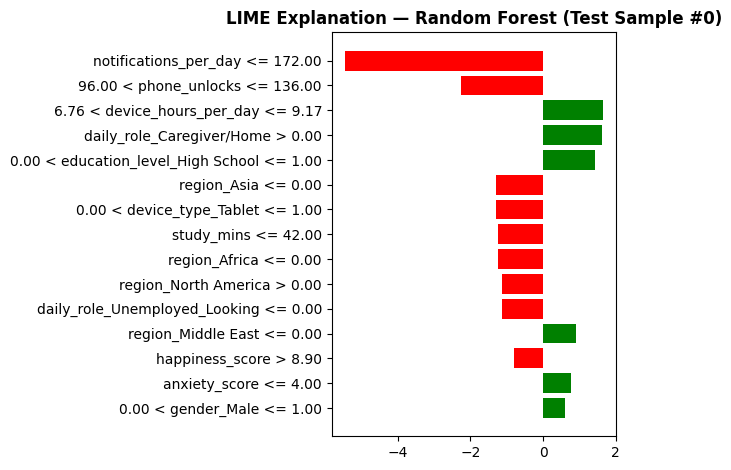

Actual    : 32.6000
RF Pred   : 30.6092
LIME Pred : 30.6092
LIME Local R²: 0.0760


In [ ]:
# ── 3b. LIME Local Explanation — Random Forest, single instance ────────────
sample_idx = 0

lime_exp_rf = lime_explainer.explain_instance(
    data_row        = X_test.values[sample_idx],
    predict_fn      = random_forest_model.predict,
    num_features    = 15,
    num_samples     = 1000
)

fig = lime_exp_rf.as_pyplot_figure()
plt.title(f'LIME Explanation — Random Forest (Test Sample #{sample_idx})',
          fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Actual    : {y_test.iloc[sample_idx]:.4f}")
print(f"RF Pred   : {y_pred_rf[sample_idx]:.4f}")
print(f"LIME Pred : {lime_exp_rf.predicted_value:.4f}")
print(f"LIME Local R²: {lime_exp_rf.score:.4f}")

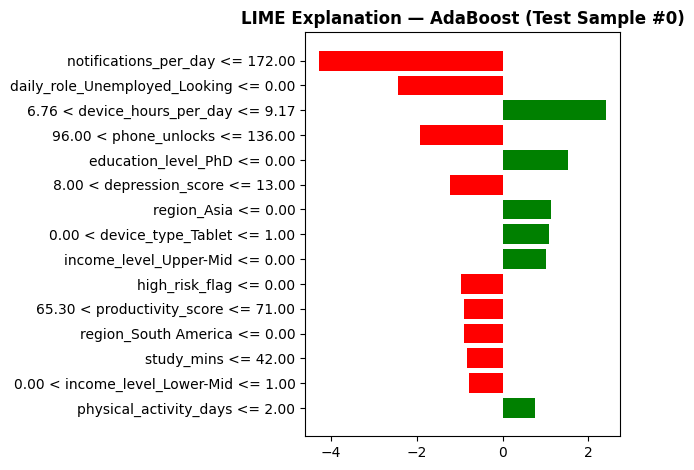

Actual      : 32.6000
Ada Pred    : 33.1960
LIME Pred   : 33.1960
LIME Local R²: 0.0803


In [ ]:
# ── 3c. LIME Local Explanation — AdaBoost, single instance ────────────────
lime_exp_ada = lime_explainer.explain_instance(
    data_row     = X_test.values[sample_idx],
    predict_fn   = abr.predict,
    num_features = 15,
    num_samples  = 1000
)

fig = lime_exp_ada.as_pyplot_figure()
plt.title(f'LIME Explanation — AdaBoost (Test Sample #{sample_idx})',
          fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Actual      : {y_test.iloc[sample_idx]:.4f}")
print(f"Ada Pred    : {y_pred[sample_idx]:.4f}")
print(f"LIME Pred   : {lime_exp_ada.predicted_value:.4f}")
print(f"LIME Local R²: {lime_exp_ada.score:.4f}")

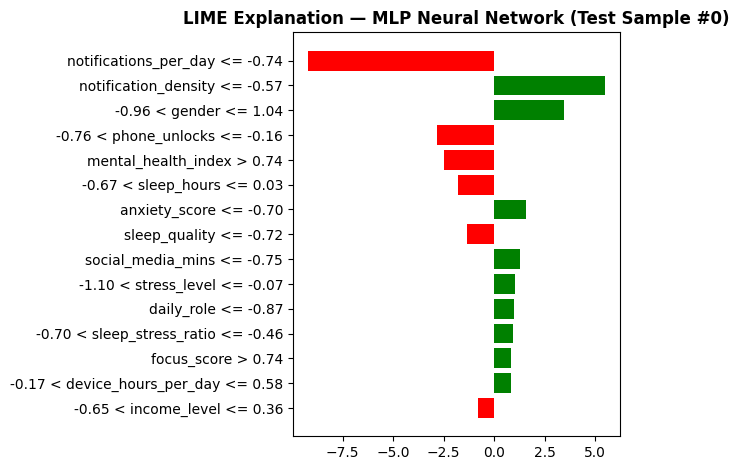

MLP Pred    : 29.9088
LIME Local R²: 0.1901


In [ ]:
# ── 3d. LIME for Neural Network (MLP sklearn) ──────────────────────────────
# LIME is model-agnostic, so it works directly on the scaled MLP

lime_explainer_nn = lime.lime_tabular.LimeTabularExplainer(
    training_data         = X_train_scaled,
    feature_names         = X_train_nn.columns.tolist(),
    mode                  = 'regression',
    random_state          = 42,
    discretize_continuous = True
)

lime_exp_mlp = lime_explainer_nn.explain_instance(
    data_row     = X_test_scaled[sample_idx],
    predict_fn   = mlp_v1.predict,
    num_features = 15,
    num_samples  = 1000
)

fig = lime_exp_mlp.as_pyplot_figure()
plt.title(f'LIME Explanation — MLP Neural Network (Test Sample #{sample_idx})',
          fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"MLP Pred    : {y_pred_v1[sample_idx]:.4f}")
print(f"LIME Local R²: {lime_exp_mlp.score:.4f}")

**Partial Dependence Plots(PDP)**

In [ ]:
# ── 4a. Select Top 6 Features for PDP (by RF SHAP importance) ─────────────
top6_features = (
    pd.Series(mean_shap_rf_vals, index=X_test.columns)
    .sort_values(ascending=False)
    .head(6)
    .index.tolist()
)

print("Top 6 features for PDP:", top6_features)

Top 6 features for PDP: ['device_hours_per_day', 'notifications_per_day', 'phone_unlocks', 'sleep_hours', 'focus_score', 'sleep_quality']


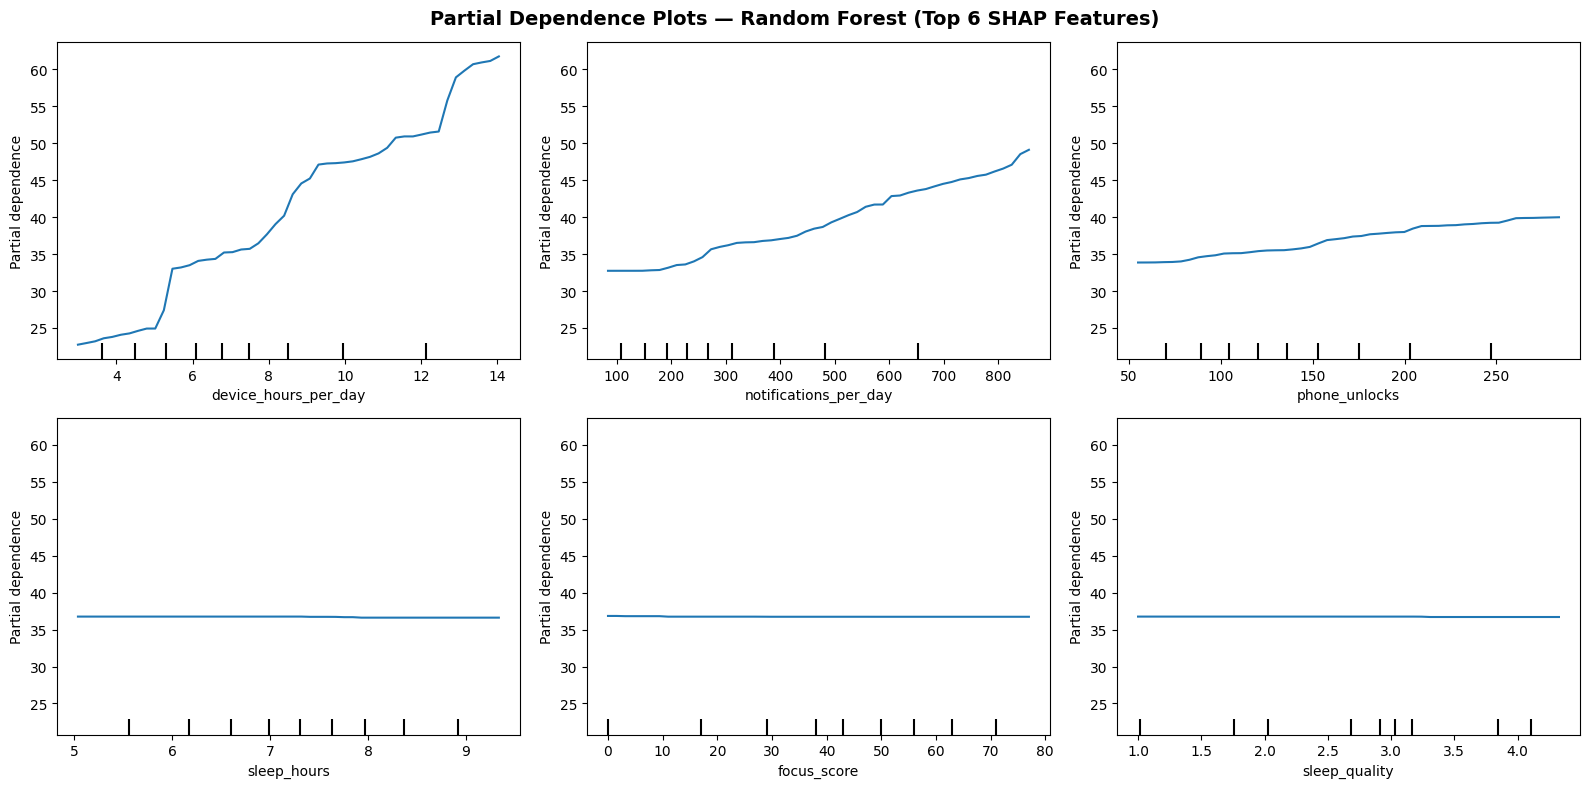

In [ ]:
# ── 4b. PDP — Random Forest ────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

PartialDependenceDisplay.from_estimator(
    random_forest_model,
    X_train,
    features      = top6_features,
    feature_names = X_train.columns.tolist(),
    kind          = 'average',          # PDP (use 'both' for PDP+ICE overlay)
    ax            = axes.flatten(),
    grid_resolution = 50,
    random_state  = 42
)

plt.suptitle('Partial Dependence Plots — Random Forest (Top 6 SHAP Features)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

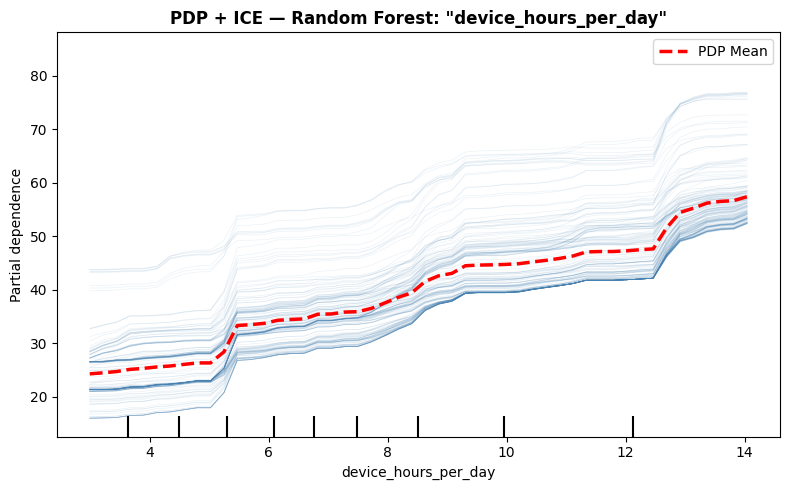

In [ ]:
# ── 4c. PDP + ICE (Individual Conditional Expectation) — Random Forest ─────
# ICE shows per-instance curves on top of the average PDP

top1_feat = top6_features[0]

fig, ax = plt.subplots(figsize=(8, 5))
PartialDependenceDisplay.from_estimator(
    random_forest_model,
    X_train,
    features        = [top1_feat],
    feature_names   = X_train.columns.tolist(),
    kind            = 'both',           # PDP + ICE overlay
    ax              = [ax],
    subsample       = 200,
    grid_resolution = 50,
    random_state    = 42,
    ice_lines_kw    = {'color': 'steelblue', 'alpha': 0.1, 'linewidth': 0.5},
    pd_line_kw      = {'color': 'red', 'linewidth': 2.5, 'label': 'PDP Mean'}
)
ax.set_title(f'PDP + ICE — Random Forest: "{top1_feat}"',
             fontsize=12, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

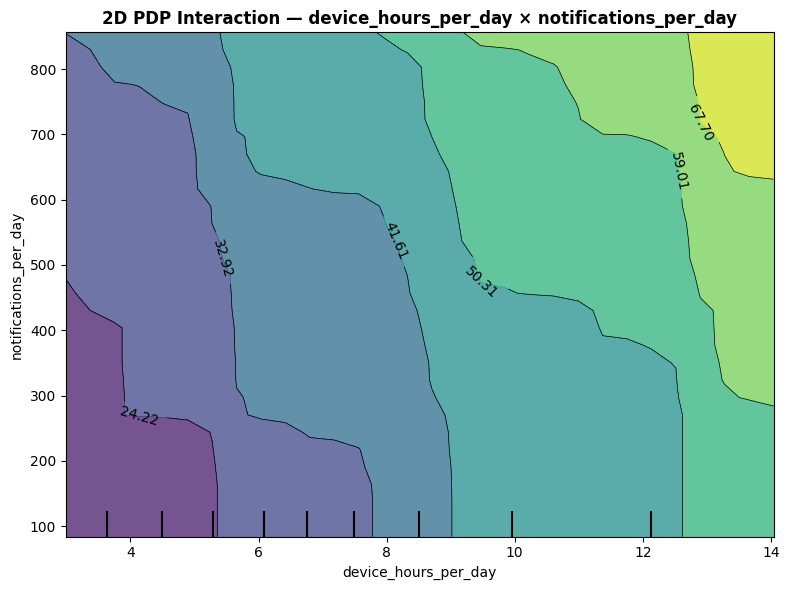

In [ ]:
# ── 4d. 2D PDP Interaction Plot — top two features ─────────────────────────
top2_pair = top6_features[:2]

fig, ax = plt.subplots(figsize=(8, 6))
PartialDependenceDisplay.from_estimator(
    random_forest_model,
    X_train,
    features        = [top2_pair],     # list-of-tuple for 2D PDP
    feature_names   = X_train.columns.tolist(),
    kind            = 'average',
    ax              = [ax],
    grid_resolution = 30,
    random_state    = 42
)
ax.set_title(f'2D PDP Interaction — {top2_pair[0]} × {top2_pair[1]}',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**XAI Summary Table**

In [ ]:
# ── 5. XAI Summary Table ───────────────────────────────────────────────────
xai_summary = pd.DataFrame({
    'Technique' : ['SHAP (TreeExplainer)', 'SHAP (TreeExplainer)', 'LIME', 'LIME', 'LIME', 'PDP', 'PDP + ICE', '2D PDP'],
    'Model'     : ['Random Forest', 'AdaBoost', 'Random Forest', 'AdaBoost', 'MLP NN', 'Random Forest', 'Random Forest', 'Random Forest'],
    'Scope'     : ['Global + Local', 'Global', 'Local', 'Local', 'Local', 'Global', 'Global + Individual', 'Global (2-feature)'],
    'Output'    : ['Beeswarm, Bar, Waterfall, Force, Dependence', 'Beeswarm',
                   'Feature weights for 1 sample', 'Feature weights for 1 sample',
                   'Feature weights for 1 sample (scaled)',
                   'Marginal effect curves', 'PDP + per-instance ICE curves',
                   'Heatmap of joint feature interaction']
})

print(xai_summary.to_string(index=False))

           Technique         Model               Scope                                      Output
SHAP (TreeExplainer) Random Forest      Global + Local Beeswarm, Bar, Waterfall, Force, Dependence
SHAP (TreeExplainer)      AdaBoost              Global                                    Beeswarm
                LIME Random Forest               Local                Feature weights for 1 sample
                LIME      AdaBoost               Local                Feature weights for 1 sample
                LIME        MLP NN               Local       Feature weights for 1 sample (scaled)
                 PDP Random Forest              Global                      Marginal effect curves
           PDP + ICE Random Forest Global + Individual               PDP + per-instance ICE curves
              2D PDP Random Forest  Global (2-feature)        Heatmap of joint feature interaction
